In [12]:
import pandas as pd
import numpy as np  
# from sodapy import Socrata
from datetime import datetime
import os
# from tqdm import tqdm
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns


pd.set_option('display.max_columns', None)
pd.set_option("display.max_colwidth", 100)
pd.set_option('display.float_format', '{:.4f}'.format)

# sys.path.append("../src")
sys.path.append(str(Path.cwd().parent))
import utils

path = os.getcwd()
print(path)

path_repo = "C:/Users/PC/Desktop/tesis/"
path_data = "C:/Users/PC/Desktop/tesis/data/"

c:\Users\PC\Desktop\python\rates_degree_work


## Tasas colocación V2

- Tabla semanal que termina en el viernes de cada semana
- H2002-2026

In [2]:
tasascol = pd.read_csv(path_data+"tasascol_H2002-2026.csv", decimal = ",")
tasascol.columns = [x.lower().replace(" ","_") for x in tasascol.columns.tolist()]
tasascol.rename(columns={'año(aaaa)_-_semana(ss)':"semana", 'fecha_(dd/mm/aaaa)':"fecha", 'nombre_cuenta':"producto", 'clasificación_tipo_establecimiento':"tipo_entidad", 
                         'tasa_(%)':"tasa", 'monto_(miles_de_millones_cop)':"monto"}, inplace =True)
tasascol["fecha"] = pd.to_datetime(tasascol["fecha"], dayfirst = True)
tasascol["anomes"] = tasascol["fecha"].astype(str).str[:7]

print(len(tasascol))
print(min(tasascol["fecha"]))
print(max(tasascol["fecha"]))

tasascol

C:\Users\PC\AppData\Local\Temp\ipykernel_8288\475460252.py:3: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  tasascol.rename(columns={'año(aaaa)_-_semana(ss)':"semana", 'fecha_(dd/mm/aaaa)':"fecha", 'nombre_cuenta':"producto", 'clasificación_tipo_establecimiento':"tipo_entidad",


48961
2002-05-03 00:00:00
2026-10-23 00:00:00


,semana,fecha,producto,tipo_entidad,tasa,monto,anomes
0,2002-18,2002-05-03,Crédito de consumo,Bancos comerciales,28.2454,69367.5781,2002-05
1,2002-18,2002-05-03,Crédito de consumo,Compañías de financiamiento comercial,27.9476,10814.8918,2002-05
2,2002-18,2002-05-03,Crédito de consumo,Cooperativas financieras,27.6983,553.7210,2002-05
3,2002-18,2002-05-03,Crédito de consumo,Organismos cooperativos,29.1372,206.7000,2002-05
4,2002-18,2002-05-03,Crédito de consumo,Total establecimientos,28.2042,80942.8908,2002-05
...,...,...,...,...,...,...,...
48956,2026-42,2026-10-23,Tasa de interés de colocación sin Tesorería,Compañías de financiamiento comercial,20.6723,224703.2947,2026-10
48957,2026-42,2026-10-23,Tasa de interés de colocación sin Tesorería,Cooperativas financieras,20.7742,46398.0847,2026-10
48958,2026-42,2026-10-23,Tasa de interés de colocación sin Tesorería,Corporaciones financieras,16.0700,499.9418,2026-10
48959,2026-42,2026-10-23,Tasa de interés de colocación sin Tesorería,Entidades financieras especiales,17.1214,25851.3850,2026-10


In [3]:
tasascol.tail(10)

,semana,fecha,producto,tipo_entidad,tasa,monto,anomes
48951,2026-42,2026-10-23,Tasa de interés de colocación Total,Cooperativas financieras,20.7742,46398.0847,2026-10
48952,2026-42,2026-10-23,Tasa de interés de colocación Total,Corporaciones financieras,16.0700,499.9418,2026-10
48953,2026-42,2026-10-23,Tasa de interés de colocación Total,Entidades financieras especiales,17.1214,25851.3850,2026-10
48954,2026-42,2026-10-23,Tasa de interés de colocación Total,Total establecimientos,16.3726,9808739.5166,2026-10
48955,2026-42,2026-10-23,Tasa de interés de colocación sin Tesorería,Bancos comerciales,16.3238,9220780.5393,2026-10
48956,2026-42,2026-10-23,Tasa de interés de colocación sin Tesorería,Compañías de financiamiento comercial,20.6723,224703.2947,2026-10
48957,2026-42,2026-10-23,Tasa de interés de colocación sin Tesorería,Cooperativas financieras,20.7742,46398.0847,2026-10
48958,2026-42,2026-10-23,Tasa de interés de colocación sin Tesorería,Corporaciones financieras,16.0700,499.9418,2026-10
48959,2026-42,2026-10-23,Tasa de interés de colocación sin Tesorería,Entidades financieras especiales,17.1214,25851.3850,2026-10
48960,2026-42,2026-10-23,Tasa de interés de colocación sin Tesorería,Total establecimientos,16.4504,9518233.2454,2026-10


In [4]:
ax = tasascol[(tasascol["producto"] == "Tasa de interés de colocación Total") & (tasascol["tipo_entidad"] == "Total establecimientos")]
ax["tasaXMonto"] = ax["tasa"] * ax["monto"]
ax = ax.groupby(['anomes', 'producto', 'tipo_entidad'])[['tasaXMonto', 'monto']].sum().reset_index()
ax["tasa"] = ax["tasaXMonto"] / ax["monto"]
del ax["tasaXMonto"]

In [5]:
tasascol[(tasascol["producto"] == "Tasa de interés de colocación Total") & (tasascol["tipo_entidad"] == "Total establecimientos")].tail(4)

,semana,fecha,producto,tipo_entidad,tasa,monto,anomes
48820,2026-39,2026-10-02,Tasa de interés de colocación Total,Total establecimientos,16.1443,11093730.7996,2026-10
48864,2026-40,2026-10-09,Tasa de interés de colocación Total,Total establecimientos,17.1819,7208968.8516,2026-10
48909,2026-41,2026-10-16,Tasa de interés de colocación Total,Total establecimientos,17.2106,6523071.2871,2026-10
48954,2026-42,2026-10-23,Tasa de interés de colocación Total,Total establecimientos,16.3726,9808739.5166,2026-10


In [6]:
# Valid ponderacion
display(tasascol[(tasascol["fecha"] == "2026-10-23") & (tasascol["producto"] == "Crédito de consumo") & (tasascol["tipo_entidad"] == "Total establecimientos")])

ax = tasascol[(tasascol["fecha"] == "2026-10-23") & (tasascol["producto"] == "Crédito de consumo")  & (tasascol["tipo_entidad"] != "Total establecimientos")]
ax["tasaXMonto"] = ax["tasa"] * ax["monto"]
print(ax["monto"].sum())
print((ax["tasaXMonto"].sum()/ax["monto"].sum()))
ax

,semana,fecha,producto,tipo_entidad,tasa,monto,anomes
48919,2026-42,2026-10-23,Crédito de consumo,Total establecimientos,21.2473,2316088.5483,2026-10


2316088.54828807
21.247338216849048


,semana,fecha,producto,tipo_entidad,tasa,monto,anomes,tasaXMonto
48916,2026-42,2026-10-23,Crédito de consumo,Bancos comerciales,21.1480,2183371.9504,2026-10,46173874.8343
48917,2026-42,2026-10-23,Crédito de consumo,Compañías de financiamiento comercial,23.7795,91381.5788,2026-10,2173011.1127
48918,2026-42,2026-10-23,Crédito de consumo,Cooperativas financieras,20.8983,41335.0191,2026-10,863830.7786


In [7]:
# Valid ponderacion
display(tasascol[(tasascol["fecha"] == "2026-10-23") & (tasascol["producto"] == "Tasa de interés de colocación Total")])# & (tasascol["tipo_entidad"] == "")])

ax = tasascol[(tasascol["fecha"] == "2026-10-23") & (~tasascol["producto"].isin(["Tasa de interés de colocación Total", "Tasa de interés de colocación Banco de la República Semanal",
                "Tasa de interés de colocación sin Tesorería"])) & (tasascol["tipo_entidad"] != "Total establecimientos")] #& (tasascol["producto"] == "Crédito de consumo")  & (tasascol["tipo_entidad"] != "Total establecimientos")]
ax["tasaXMonto"] = ax["tasa"] * ax["monto"]
ax = ax.groupby(["semana", "fecha", "tipo_entidad"])[["tasaXMonto", "monto"]].sum().reset_index()
ax["tasa"] = ax["tasaXMonto"] / ax["monto"]

print(ax["monto"].sum())
# print((ax["tasaXMonto"].sum()/ax["monto"].sum()))
ax

,semana,fecha,producto,tipo_entidad,tasa,monto,anomes
48949,2026-42,2026-10-23,Tasa de interés de colocación Total,Bancos comerciales,16.2476,9511286.8104,2026-10
48950,2026-42,2026-10-23,Tasa de interés de colocación Total,Compañías de financiamiento comercial,20.6723,224703.2947,2026-10
48951,2026-42,2026-10-23,Tasa de interés de colocación Total,Cooperativas financieras,20.7742,46398.0847,2026-10
48952,2026-42,2026-10-23,Tasa de interés de colocación Total,Corporaciones financieras,16.0700,499.9418,2026-10
48953,2026-42,2026-10-23,Tasa de interés de colocación Total,Entidades financieras especiales,17.1214,25851.3850,2026-10
48954,2026-42,2026-10-23,Tasa de interés de colocación Total,Total establecimientos,16.3726,9808739.5166,2026-10


10255687.356680458


,semana,fecha,tipo_entidad,tasaXMonto,monto,tasa
0,2026-42,2026-10-23,Bancos comerciales,170974467.9158,9941192.1559,17.1986
1,2026-42,2026-10-23,Compañías de financiamiento comercial,5243716.7925,237025.6063,22.1230
2,2026-42,2026-10-23,Cooperativas financieras,1125331.2582,51118.2677,22.0143
3,2026-42,2026-10-23,Corporaciones financieras,8034.0651,499.9418,16.0700
4,2026-42,2026-10-23,Entidades financieras especiales,442612.2204,25851.3850,17.1214


In [8]:
tasascol2 = tasascol.copy()

## Filters

In [184]:
tasascol = tasascol2.copy()
# tasascol["vari_monto_m1"] = tasascol.groupby(["producto", "tipo_entidad"])["monto"].pct_change(1)*100
# tasascol["vari_tasa_m1"] = tasascol.groupby(["producto", "tipo_entidad"])["tasa"].pct_change(1)*100
# tasascol["monto_r12"] = tasascol.groupby(["producto", "tipo_entidad"])["monto"].shift(12)
# tasascol["tasa_r12"] = tasascol.groupby(["producto", "tipo_entidad"])["tasa"].shift(12)
# tasascol["y_vari_anual_monto"] = 100*((tasascol["monto"] / tasascol["monto_r12"]) - 1)
# tasascol["vari_anual_tasa"] = 100*((tasascol["tasa"] / tasascol["tasa_r12"]) - 1)

print(len(tasascol))
tasascol = tasascol[(tasascol["tipo_entidad"] == "Bancos comerciales")]
print(len(tasascol))
tasascol = tasascol[(~tasascol["producto"].isin(["Tasa de interés de colocación Total", "Tasa de interés de colocación Banco de la República Semanal",
                                                 "Tasa de interés de colocación sin Tesorería"]))]
print(len(tasascol))
tasascol = tasascol[(tasascol["fecha"] >= "2004-01-01")]
print(len(tasascol))
tasascol = tasascol[(tasascol["fecha"] <= "2026-09-30")]
print(len(tasascol))


# TEMPORAL
tasascol = tasascol[tasascol["producto"] == "Créditos Comerciales (Ordinario)"]
tasascol = tasascol[tasascol["tipo_entidad"] == "Bancos comerciales"]
print(len(tasascol))

# tasascol.drop(columns = ["monto_r12", "tasa_r12", "semana", "tipo_entidad"], inplace = True)

print(min(tasascol["fecha"]))

tasascol.tail(15)

48961
10776
6942
6504
6476
1187
2004-01-02 00:00:00


,semana,fecha,producto,tipo_entidad,tasa,monto,anomes
48126,2026-24,2026-06-19,Créditos Comerciales (Ordinario),Bancos comerciales,15.4551,2792986.3222,2026-06
48171,2026-25,2026-06-26,Créditos Comerciales (Ordinario),Bancos comerciales,15.3761,4840067.4216,2026-06
48216,2026-26,2026-07-03,Créditos Comerciales (Ordinario),Bancos comerciales,15.6758,2776175.4313,2026-07
48261,2026-27,2026-07-10,Créditos Comerciales (Ordinario),Bancos comerciales,15.6905,2456369.7080,2026-07
48306,2026-28,2026-07-17,Créditos Comerciales (Ordinario),Bancos comerciales,15.7362,2958833.2362,2026-07
48351,2026-29,2026-07-24,Créditos Comerciales (Ordinario),Bancos comerciales,15.8081,2771331.2959,2026-07
48395,2026-30,2026-07-31,Créditos Comerciales (Ordinario),Bancos comerciales,15.6046,5016812.6048,2026-07
48440,2026-31,2026-08-07,Créditos Comerciales (Ordinario),Bancos comerciales,15.6623,2094420.2671,2026-08
48485,2026-32,2026-08-14,Créditos Comerciales (Ordinario),Bancos comerciales,15.3991,2727419.2805,2026-08
48530,2026-33,2026-08-21,Créditos Comerciales (Ordinario),Bancos comerciales,15.0970,3756944.4107,2026-08


In [18]:
qwe

NameError: name 'qwe' is not defined

In [ ]:
# tasascol.tail(200).to_csv(path_data + "tasascol_sample.csv")

## BANREP

In [19]:
def calc_viernes(df, columna_fecha='Fecha', saltar_fin_de_semana=False):
    df_resultado = df.copy()
    
    # Asegurar formato datetime
    fechas_dt = pd.to_datetime(df_resultado[columna_fecha])
    dia_semana = fechas_dt.dt.weekday
    
    # Calcular días de diferencia hasta el viernes (Viernes = 4)
    if saltar_fin_de_semana:
        dias_al_viernes = np.where(dia_semana > 4, 11 - dia_semana, 4 - dia_semana)
    else:
        dias_al_viernes = 4 - dia_semana
        
    # Asignar la nueva columna
    df_resultado["Fecha_viernes"] = fechas_dt + pd.to_timedelta(dias_al_viernes, unit='d')
    
    return df_resultado


def filtrar_dias_habiles(df, columna_fecha='Fecha'):
    df_resultado = df.copy()
    
    # Asegurar que la columna tenga formato datetime
    fechas_dt = pd.to_datetime(df_resultado[columna_fecha])
    
    # .dt.weekday devuelve 0=Lunes hasta 6=Domingo. 
    # Los días menores a 5 son de lunes a viernes.
    mascara_habiles = fechas_dt.dt.weekday < 5
    
    # Retornar el DataFrame filtrado
    return df_resultado[mascara_habiles].copy()

In [20]:
ph = [x for x in os.listdir(path_data+"BANREP/") if "trm" not in x]
print(len(ph))
ph

17


['agregados_crediticios.xlsx',
 'agregados_monetarios.xlsx',
 'indice_precios_vivienda.xlsx',
 'inflacion_consumidor.xlsx',
 'inflacion_consumidor2.xlsx',
 'ipp.xlsx',
 'ipp2.xlsx',
 'mercado_laboral.xlsx',
 'pib.xlsx',
 'pulso.xlsx',
 'reservas_internacionales.xlsx',
 'sector_externo.xlsx',
 'sector_externo2.xlsx',
 'tasas_de_interes.xlsx',
 'tasas_de_interes2.xlsx',
 'tasas_de_interes3.xlsx',
 'unidad_valor_real.xlsx']

In [ ]:
banrep = pd.read_excel(path_data+"BANREP/trm.xlsx", decimal = ",")
banrep = banrep.iloc[1:(len(banrep)-1)].dropna(subset = "Fecha")

for i in ph:
    tmp = pd.read_excel(path_data+"BANREP/"+i, decimal = ",")
    tmp = tmp.iloc[1:(len(tmp)-1)].dropna(subset = "Fecha")
    
    banrep["Fecha"] = banrep["Fecha"].astype(str)
    tmp["Fecha"] = tmp["Fecha"].astype(str)
    banrep = pd.merge(banrep, tmp, on = "Fecha", how = "outer")

    banrep.columns = [x.replace("_x","").replace("_y","") for x in banrep.columns.tolist()]
    banrep = banrep.loc[:, ~banrep.columns.duplicated()]

    print(f"{i}: {tmp.shape}")

print("\n", banrep.shape)
# banrep1.columns = [x.lower().replace("í","i").replace("ó","o").replace("é","e").replace(" ", "_") for x in banrep1.columns]
banrep = banrep.replace({'-':np.nan})
banrep["Fecha"] = pd.to_datetime(banrep["Fecha"], dayfirst = True)
banrep["anomes"] = banrep["Fecha"].dt.strftime("%Y-%m")

banrep = banrep.loc[:, ~banrep.columns.duplicated()]
banrep = banrep.sort_values("Fecha")

for i in [x for x in banrep if x not in ["Fecha", "anomes"]]:
    try:
        banrep[i] = banrep[i].astype(float)
    except:
        banrep[i] = banrep[i].str.replace(".","").str.replace(",",".").astype(float)

banrep = banrep[banrep["Fecha"] <= max(tasascol["fecha"])]

banrep.columns = [x.replace("Tasa de Certificado de Depósito a Término","Tasa CDT").replace("Tasa de Depósitos a Término Fijo","Tasa CDT").
                   replace("Tasa Representativa del Mercado (TRM)","TRM").replace("Indicador Bancario de Referencia (IBR)","IBR").
                   replace("Índice de precios al consumidor (IPC)","IPC").replace("Tasa de política monetaria","TPM").
                   replace("Captaciones a través de CDT","Tasa CDT").replace("Índice de Precios del Productor (IPP),","IPP:").
                   replace("Depósitos en el sistema financiero","Depós. en SF").replace("Índice de precios de la vivienda","IPViv").
                   replace("Producto Interno Bruto (PIB) nominal, Trimestral, metodología: 2015, Ajuste estacional(Dato fin de trimestre)","PIB nominal (Dato fin de trimestre)").
                   replace("Producto Interno Bruto (PIB) real, Trimestral, base: 2015, Ajuste estacional(Dato fin de trimestre)","PIB real (Dato fin de trimestre)") for x in banrep.columns]

banrep.rename(columns = {'Índice de Precios al Consumidor (IPC)(mes)':"IPC(mes)"}, inplace = True)

dels = [x for x in banrep if "Variación porcentual" in x]
banrep.drop(columns = dels, inplace = True)
print("\nAfter dels:", banrep.shape)

banrep = calc_viernes(banrep, columna_fecha='Fecha')
# banrep = filtrar_dias_habiles(banrep, columna_fecha='Fecha')

banrep = banrep[banrep["Fecha"] < "2026-10-01"]

print("After dias habiles:", banrep.shape)


banrep = banrep[["Fecha", "Fecha_viernes"] + [x for x in banrep if x not in ["Fecha", "Fecha_viernes"]]]

# Variables de no interes
cols = [
'Euro - COP/EUR - Tasa media(Dato fin de semana)', 'Euro - COP/EUR - Tasa media(Dato fin de mes)', 
'Euro - COP/EUR - Tasa media(Dato fin de trimestre)', 'Euro - COP/EUR - Tasa media(Dato fin de semestre)', 'Euro - COP/EUR - Tasa media(Dato fin de año)', 
'Libra esterlina - COP/GBP - Tasa media(Dato fin de semana)', 'Libra esterlina - COP/GBP - Tasa media(Dato fin de mes)', 
'Libra esterlina - COP/GBP - Tasa media(Dato fin de trimestre)', 'Libra esterlina - COP/GBP - Tasa media(Dato fin de semestre)', 'Libra esterlina - COP/GBP - Tasa media(Dato fin de año)',
'TRM(Dato fin de semana)', 'TRM(Dato fin de mes)', 'TRM(Dato fin de trimestre)', 'TRM(Dato fin de semestre)', 'TRM(Dato fin de año)', 'TRM(Promedio mes corrido)', 
'TRM(Promedio mensual)', 'TRM(Promedio anual)', 'Índice de Precios al Consumidor (IPC)(Dato fin de trimestre)', 
'Índice de Precios al Consumidor (IPC)(Dato fin de semestre)', 'Índice de Precios al Consumidor (IPC)(Dato fin de año)','Índice de Precios al Consumidor (IPC)(Dato fin de trimestre)', 
'IPC: Alimentos y bebidas no alcohólicas(Dato fin de semestre)', 'IPC: Alimentos y bebidas no alcohólicas(Dato fin de año)', 
'IPC: Alojamiento, agua, electricidad, gas y otros combustibles(Dato fin de trimestre)', 'IPC: Alojamiento, agua, electricidad, gas y otros combustibles(Dato fin de semestre)', 
'IPC: Alojamiento, agua, electricidad, gas y otros combustibles(Dato fin de año)', 
'IPC: Muebles, artículos para el hogar y para la conservación ordinaria del hogar(Dato fin de trimestre)', 
'IPC: Muebles, artículos para el hogar y para la conservación ordinaria del hogar(Dato fin de semestre)', 
'IPC: Muebles, artículos para el hogar y para la conservación ordinaria del hogar(Dato fin de año)', 'IPC: Transporte(Dato fin de trimestre)', 
'IPC: Transporte(Dato fin de semestre)', 'IPC: Transporte(Dato fin de año)', 'IPC: Información y comunicación(Dato fin de trimestre)', 
'IPC: Educación(Dato fin de mes)', 'IPC: Educación(Dato fin de trimestre)',
'IPC: Educación(Dato fin de semestre)', 'IPC: Educación(Dato fin de año)', 'IPC: Bienes y servicios diversos(Dato fin de trimestre)', 
'IPC: Bienes y servicios diversos(Dato fin de semestre)', 'IPC: Bienes y servicios diversos(Dato fin de año)', 'IPC: Bogotá, D.C.(Dato fin de trimestre)', 
'IPC: Bogotá, D.C.(Dato fin de semestre)', 'IPC: Bogotá, D.C.(Dato fin de año)', 'IPC: Cali(Dato fin de trimestre)', 'IPC: Cali(Dato fin de semestre)', 
'IPC: Cali(Dato fin de año)', 'IPC: Bucaramanga(Dato fin de trimestre)', 'IPC: Bucaramanga(Dato fin de semestre)', 'IPC: Bucaramanga(Dato fin de año)', 
'IPC: Sin alimentos(Dato fin de trimestre)', 'IPC: Sin alimentos(Dato fin de semestre)', 'IPC: Sin alimentos(Dato fin de año)', 
'IPC: Regulados(Dato fin de trimestre)', 'IPC: Regulados(Dato fin de semestre)', 'IPC: Regulados(Dato fin de año)',
'IBR a 1 mes, efectiva(Promedio semanal)', 'IBR overnight, efectiva(Promedio semanal)', 
'IBR a 3 meses, efectiva(Promedio semanal)', 'IBR a 6 meses, efectiva(Promedio semanal)', 'IBR a 12 meses, efectiva(Promedio semanal)',
'TPM(Dato fin de semana)', 'TPM(Dato mes)', 'TPM(Dato fin de mes)', 'TPM(Dato fin de trimestre)', 'TPM(Dato fin de semestre)', 'TPM(Dato fin de año)', 
'TPM(Dato semanal)', 'Tasa CDT (DTF) a 90 días, semanal(Dato fin de semana)', 
'Tasa CDT (DTF) a 90 días, semanal(Dato fin de mes)', 'Tasa CDT (DTF) a 90 días, semanal(Dato fin de trimestre)', 'Tasa CDT (DTF) a 90 días, semanal(Dato fin de semestre)', 
'Tasa CDT (DTF) a 90 días, semanal(Dato fin de año)', 'Tasa CDT (DTF) a 90 días, semanal(Dato semanal)', 'Tasa CDT (DTF) a 90 días, semanal(Promedio semanal)', 
'Tasa CDT (DTF) a 90 días, mensual(Dato fin de mes)', 'Tasa CDT (DTF) a 90 días, mensual(Dato fin de trimestre)', 'Tasa CDT (DTF) a 90 días, mensual(Dato fin de semestre)', 
'Tasa CDT (DTF) a 90 días, mensual(Dato fin de año)', 'Tasa de interés fin de mes de los certificados de depósito a término a 90 días, CDT 90 para bancos y corporaciones(Dato fin de trimestre)', 
'Tasa de interés fin de mes de los certificados de depósito a término a 90 días, CDT 90 para bancos y corporaciones(Dato fin de semestre)',
'Tasa de interés fin de mes de los certificados de depósito a término a 90 días, CDT 90 para bancos y corporaciones(Dato fin de año)',
"IPC: Alimentos y bebidas no alcohólicas(Dato fin de trimestre)", "IPC: Información y comunicación(Dato fin de semestre)", "IPC: Información y comunicación(Dato fin de año)",
"Prime(Promedio mes corrido)", "Prime(Promedio anual)"
]
banrep.drop(columns = cols, inplace = True)

banrep.columns = [x.replace("Dato fin de","").replace("(Dato diario)","(diario)").replace("semanal( semana)","(semana)").replace("( semana)","(semana)").
                  replace("trimestral( trimestre)","(trimestre)").replace("( trimestre)","(trimestre)").replace("( mes)","(mes)").replace("Semanal(Dato semanal)","(semana)").
                  replace("semanal(Dato semanal)","(semana)").replace("diaria(diario)","(diario)") for x in banrep.columns]

print("\n", banrep["Fecha"].min(), "|", banrep["Fecha"].max())
print(banrep.shape)
banrep.tail(9)

agregados_crediticios.xlsx: (1276, 6)
agregados_monetarios.xlsx: (2335, 16)
indice_precios_vivienda.xlsx: (337, 6)
inflacion_consumidor.xlsx: (855, 17)
inflacion_consumidor2.xlsx: (867, 126)
ipp.xlsx: (328, 2)
ipp2.xlsx: (681, 12)
mercado_laboral.xlsx: (309, 6)
pib.xlsx: (86, 7)
pulso.xlsx: (166, 10)
reservas_internacionales.xlsx: (801, 3)
sector_externo.xlsx: (525, 17)
sector_externo2.xlsx: (562, 15)
tasas_de_interes.xlsx: (4897, 18)
tasas_de_interes2.xlsx: (9827, 23)
tasas_de_interes3.xlsx: (15689, 35)
unidad_valor_real.xlsx: (3848, 3)

 (16107, 325)

After dels: (16056, 254)
After dias habiles: (16056, 255)

 1954-07-31 00:00:00 | 2026-09-25 00:00:00
(16056, 169)


C:\Users\PC\AppData\Local\Temp\ipykernel_8288\3358969397.py:43: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  banrep.drop(columns = dels, inplace = True)
C:\Users\PC\AppData\Local\Temp\ipykernel_8288\1419917051.py:6: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  dia_semana = fechas_dt.dt.weekday
C:\Users\PC\AppData\Local\Temp\ipykernel_8288\1419917051.py:15: Pandas4Warning: 'd' is deprecated and will be removed in a future version. Please use 'D' instead of 'd'.
  df_resultado["Fecha_viernes"] = fechas_dt + pd.to_timedelta(dias_al_viernes, unit='d')
C:\Users\PC\AppData\Local\Temp\ipykernel_8288\3358969397.py:92: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https:

,Fecha,Fecha_viernes,TRM(diario),Euro - COP/EUR - Tasa media(diario),Libra esterlina - COP/GBP - Tasa media(diario),"Cartera comercial en moneda legal, (semana)","Cartera comercial en moneda extranjera , expresada en pesos, (semana)","Cartera consumo en moneda legal, (semana)","Cartera microcrédito en moneda legal, (semana)","Cartera hipotecaria en moneda legal, (semana)","Efectivo, (semana)","Reserva Bancaria, (semana)","Base monetaria, (semana)","Depós. en SF, cuentas corrientes del sector privado, (semana)","Depós. en SF, cuentas corrientes del sector público, (semana)","Depós. en SF, cuentas corrientes total, (semana)","Cuasidineros - cuentas de ahorro, (semana)","Cuasidineros - CDT, (semana)","Cuasidineros, total, (semana)","Otros depósitos a la vista, (semana)","Depósitos fiduciarios, (semana)","Depós. en SF, cédulas, (semana)","Depós. en SF, bonos, (semana)","Depós. en SF, total depósitos, (semana)","Depósitos restringidos, (semana)","IPViv usada (IPVU), Índice real - (trimestre)",IPViv nueva (IPVNBR) - Índice real - Bogotá(mes),IPViv nueva (IPVNBR) - Índice real - Medellín(mes),IPViv nueva (IPVNBR) - Índice real - Cali(mes),IPViv nueva (IPVNBR) - Índice real - Agregado(mes),Inflación total anual(mes),Inflación sin alimentos(mes),Inflación sin alimentos ni regulados(mes),"Inflación de bienes, sin alimentos ni regulados(mes)","Inflación de servicios, sin alimentos ni regulados(mes)",Inflación de regulados(mes),"Inflación, Prendas de vestir y calzado(mes)","Inflación, Muebles, artículos para el hogar y para la conservación ordinaria del hogar(mes)","Inflación, Salud(mes)","Inflación, Información y comunicación(mes)","Inflación, Recreación y cultura(mes)","Inflación, Educación(mes)","Inflación, Restaurantes y hoteles(mes)","Inflación, Bienes y servicios diversos(mes)",Inflación de alimentos(mes),Inflación de alimentos y regulados(mes),Índice de Precios al Consumidor (IPC)(mes),IPC: Alimentos y bebidas no alcohólicas(mes),"IPC: Alojamiento, agua, electricidad, gas y otros combustibles(mes)","IPC: Muebles, artículos para el hogar y para la conservación ordinaria del hogar(mes)",IPC: Transporte(mes),IPC: Información y comunicación(mes),IPC: Bienes y servicios diversos(mes),"IPC: Bogotá, D.C.(mes)",IPC: Cali(mes),IPC: Bucaramanga(mes),IPC: Sin alimentos(mes),IPC: Regulados(mes),IPC: de alimentos(mes),Índice de Precios del Productor (IPP)(mes),IPP: Producción nacional - Explotación de minas y canteras(mes),IPP: Oferta interna - Total(mes),"IPP: Oferta interna - Agricultura, ganadería, caza, silvicultura y pesca(mes)",IPP: Oferta interna - Industria manufactureras(mes),IPP: Según procedencia - producidos y consumidos(mes),IPP: Según procedencia - Importados(mes),IPP: Según procedencia - Exportados(mes),IPP: Según uso o destino económico - Consumo intermedio(mes),IPP: Según uso o destino económico - Consumo final(mes),IPP: Según uso o destino económico - Bienes de capital(mes),Tasa global de participación(mes),"Tasa de ocupación, según nivel educativo: sin educación superior(mes)","Tasa de desempleo, según nivel educativo: sin educación superior(mes)",Tasa de desempleo - total nacional(mes),Tasa de ocupación - total nacional(mes),PIB nominal (trimestre),PIB real (trimestre),"Consumo final, real(trimestre)","Formación bruta de capital, real(trimestre)","Exportaciones, real(trimestre)","Importaciones, real(trimestre)",Pulso Económico Regional - Comercio(mes),Pulso Económico Regional - Transporte(mes),Pulso Económico Regional - Agropecuario(mes),Pulso Económico Regional - Financiero(mes),Pulso Económico Regional - Vivienda(mes),Pulso Económico Regional - Nacional(mes),Pulso Económico Regional - Antioquia(mes),Pulso Económico Regional - Suroccidente(mes),Pulso Económico Regional - Bogotá(mes),Reservas internacionales brutas(mes),Reservas internacionales netas(mes),Balanza de pagos - Importaciones totales (Bienes) - (trimestre),Balanza de pagos - Exportaciones totales (Bienes) - (trimestre),Balanza de pagos - Flujo de Inversión Extran

In [234]:
print([x for x in banrep if "IPC" in x])

['IPC(mes)', 'IPC: Alimentos y bebidas no alcohólicas(mes)', 'IPC: Alojamiento, agua, electricidad, gas y otros combustibles(mes)', 'IPC: Muebles, artículos para el hogar y para la conservación ordinaria del hogar(mes)', 'IPC: Transporte(mes)', 'IPC: Información y comunicación(mes)', 'IPC: Bienes y servicios diversos(mes)', 'IPC: Bogotá, D.C.(mes)', 'IPC: Cali(mes)', 'IPC: Bucaramanga(mes)', 'IPC: Sin alimentos(mes)', 'IPC: Regulados(mes)', 'IPC: de alimentos(mes)']


In [43]:
banrep_dia = banrep[["Fecha", "Fecha_viernes"] + [x for x in banrep if "(diario)" in x]]

cols_sum = ['Tasa CDT por red de oficinas - Monto, (diario)', 'Tasa CDT por tesorería - Monto, (diario)', 'Operaciones interbancarias - Monto(diario)', 
            'Tasa CDT (CDT) a 120 días - Monto, (diario)', 'Tasa CDT (CDAT) entre 15 y 29 días - Monto, (diario)', 'Tasa CDT (CDAT) a 30 días - Monto, (diario)', 
            'Tasa CDT (CDAT) entre 31 y 90 días - Monto, (diario)', 'Tasa CDT (CDAT) entre 91 y 180 días - Monto, (diario)', 'Tasa CDT (CDT) a 30 días - Monto, (diario)', 
            'Tasa CDT (CDT) a 360 días - Monto, (diario)']
cols_prom = ['TRM(diario)', 'Euro - COP/EUR - Tasa media(diario)', 'Libra esterlina - COP/GBP - Tasa media(diario)', 'IBR a 1 mes, efectiva(diario)', 
             'Tasa CDT por red de oficinas, (diario)', 'Tasa CDT por tesorería, (diario)', 'Prime(diario)', 'IBR overnight, efectiva(diario)', 'IBR a 3 meses, efectiva(diario)', 
             'IBR a 6 meses, efectiva(diario)', 'IBR a 12 meses, efectiva(diario)', 'Tasa CDT (CDAT) entre 15 y 29 días, (diario)', 'Tasa CDT (CDAT) a 30 días, (diario)', 
             'Tasa CDT (CDAT) entre 31 y 90 días, (diario)', 'Tasa CDT (CDAT) entre 91 y 180 días, (diario)', 'TPM(diario)', 'Tasa CDT (DTF) a 90 días, semanal(diario)', 
             'Tasa interbancaria (TIB)(diario)', 'Tasa CDT (CDT) a 360 días, (diario)', 'Tasa CDT (CDT) a 30 días, (diario)', 'Tasa CDT (CDT) a 120 días, (diario)']

print(banrep_dia.shape)
dicc = {x:"sum" for x in cols_sum}
dicc.update({x:"mean" for x in cols_prom})
banrep_dia = banrep_dia.groupby("Fecha_viernes").agg(dicc).reset_index()
print(banrep_dia.shape)
banrep_dia.tail(8)

# banrep[[x for x in banrep_dia if x not in cols_sum]]

(16061, 33)
(16061, 33)
(2665, 32)


,Fecha_viernes,"Tasa CDT por red de oficinas - Monto, (diario)","Tasa CDT por tesorería - Monto, (diario)",Operaciones interbancarias - Monto(diario),"Tasa CDT (CDT) a 120 días - Monto, (diario)","Tasa CDT (CDAT) entre 15 y 29 días - Monto, (diario)","Tasa CDT (CDAT) a 30 días - Monto, (diario)","Tasa CDT (CDAT) entre 31 y 90 días - Monto, (diario)","Tasa CDT (CDAT) entre 91 y 180 días - Monto, (diario)","Tasa CDT (CDT) a 30 días - Monto, (diario)","Tasa CDT (CDT) a 360 días - Monto, (diario)",TRM(diario),Euro - COP/EUR - Tasa media(diario),Libra esterlina - COP/GBP - Tasa media(diario),"IBR a 1 mes, efectiva(diario)","Tasa CDT por red de oficinas, (diario)","Tasa CDT por tesorería, (diario)",Prime(diario),"IBR overnight, efectiva(diario)","IBR a 3 meses, efectiva(diario)","IBR a 6 meses, efectiva(diario)","IBR a 12 meses, efectiva(diario)","Tasa CDT (CDAT) entre 15 y 29 días, (diario)","Tasa CDT (CDAT) a 30 días, (diario)","Tasa CDT (CDAT) entre 31 y 90 días, (diario)","Tasa CDT (CDAT) entre 91 y 180 días, (diario)",TPM(diario),"Tasa CDT (DTF) a 90 días, semanal(diario)",Tasa interbancaria (TIB)(diario),"Tasa CDT (CDT) a 360 días, (diario)","Tasa CDT (CDT) a 30 días, (diario)","Tasa CDT (CDT) a 120 días, (diario)"
2657,2026-08-14,8946059.6400,4332857.2200,7184533.6500,571596.7300,33500.0000,1987.0000,51019.0000,182019.6100,1341976.7100,2145035.5400,3130.2943,3618.7542,4234.4395,11.9976,10.2940,12.7320,6.7500,12.0012,12.0814,12.2508,12.3172,1.4000,0.4600,4.8400,9.5700,12.0000,10.1000,11.9820,12.3560,9.2720,10.0180
2658,2026-08-21,7881536.2300,2121653.5800,5435562.4900,529827.2300,15163.0000,681.0000,24032.0000,4427.9200,1067435.7200,1150618.2500,3081.2529,3588.8508,4190.8329,12.0015,10.4100,12.5525,6.7500,12.0092,12.0960,12.2488,12.3010,0.3833,0.4133,3.3775,10.0175,12.0000,10.1900,11.9625,11.9250,9.3750,10.2225
2659,2026-08-28,8765344.2500,2099756.8800,7255456.6600,391107.8500,991.0000,6990.0000,55191.0000,329064.0900,1164505.8800,1322362.7800,3122.0571,3634.4121,4244.1980,12.0010,10.3840,12.4640,6.7500,11.9954,12.0976,12.2246,12.2698,1.4000,0.4650,5.9440,9.9240,12.0000,10.2100,11.9760,12.0200,9.2780,9.9000
2660,2026-09-04,8888615.6900,1298313.6900,6925091.3300,331246.8500,16000.0000,3649.0000,127174.0000,6349.4700,1245680.9000,1023921.4300,3162.1186,3671.3322,4276.3296,12.0060,10.2680,12.4060,6.7500,11.9912,12.0986,12.2178,12.3322,0.1000,0.4580,6.4260,9.9880,12.0000,10.1900,11.9680,11.8680,9.2880,9.9320
2661,2026-09-11,9478869.8300,2088056.6100,6784770.6400,418198.3800,4020.0000,17308.0000,57866.0000,63641.6300,1225677.2900,1266610.6900,3101.9500,3606.2782,4199.9493,12.0442,10.4640,12.4620,6.7500,11.9918,12.1498,12.2984,12.3924,1.1750,0.4900,6.6480,10.0280,12.0000,10.0500,11.9720,11.9720,9.3680,10.2960
2662,2026-09-18,8326331.2600,4199587.7000,6479798.1500,349072.2300,55966.0000,3798.0000,77546.0000,97100.7800,1115664.3100,1744114.0400,3135.4357,3605.2090,4203.7741,12.1054,10.4700,12.5920,6.8500,12.0010,12.2292,12.3938,12.5208,0.7667,0.4620,7.4980,9.9420,12.0000,10.2200,11.9720,12.1660,9.4820,10.1760
2663,2026-09-25,8376553.6500,2643217.0000,6277695.9600,505993.1000,0.0000,12733.0000,37190.0000,187745.4000,1157109.7500,1021833.6700,3257.4043,3717.7783,4324.5809,12.0962,10.3720,12.5900,7.0000,12.0022,12.2304,12.3728,12.4828,NaN,0.4780,7.6060,9.8200,12.0000,10.2600,11.9880,12.0420,9.4760,10.5340
2664,2026-10-02,6149842.1500,1511413.7400,3745926.2100,334934.2100,4720.0000,1688.0000,46585.0000,4143.1400,1083003.8000,742210.2000,3332.5733,3783.8441,4415.5949,12.0830,10.4300,12.8300,7.0000,12.0097,12.2300,12.3643,12.5150,0.5250,0.5233,7.3167,9.9833,12.0000,10.3800,12.0000,12.0100,9.6433,10.5467


In [42]:
print([x for x in banrep_dia if x not in cols_sum])

['Fecha', 'Fecha_viernes', 'TRM(diario)', 'Euro - COP/EUR - Tasa media(diario)', 'Libra esterlina - COP/GBP - Tasa media(diario)', 'IBR a 1 mes, efectiva(diario)', 'Tasa CDT por red de oficinas, (diario)', 'Tasa CDT por tesorería, (diario)', 'Prime(diario)', 'IBR overnight, efectiva(diario)', 'IBR a 3 meses, efectiva(diario)', 'IBR a 6 meses, efectiva(diario)', 'IBR a 12 meses, efectiva(diario)', 'Tasa CDT (CDAT) entre 15 y 29 días, (diario)', 'Tasa CDT (CDAT) a 30 días, (diario)', 'Tasa CDT (CDAT) entre 31 y 90 días, (diario)', 'Tasa CDT (CDAT) entre 91 y 180 días, (diario)', 'TPM(diario)', 'Tasa CDT (DTF) a 90 días, semanal(diario)', 'Tasa interbancaria (TIB)(diario)', 'Tasa CDT (CDT) a 360 días, (diario)', 'Tasa CDT (CDT) a 30 días, (diario)', 'Tasa CDT (CDT) a 120 días, (diario)']


In [40]:
print([x for x in banrep_dia if "Monto" in x])

['Tasa CDT por red de oficinas - Monto, (diario)', 'Tasa CDT por tesorería - Monto, (diario)', 'Operaciones interbancarias - Monto(diario)', 'Tasa CDT (CDT) a 120 días - Monto, (diario)', 'Tasa CDT (CDAT) entre 15 y 29 días - Monto, (diario)', 'Tasa CDT (CDAT) a 30 días - Monto, (diario)', 'Tasa CDT (CDAT) entre 31 y 90 días - Monto, (diario)', 'Tasa CDT (CDAT) entre 91 y 180 días - Monto, (diario)', 'Tasa CDT (CDT) a 30 días - Monto, (diario)', 'Tasa CDT (CDT) a 360 días - Monto, (diario)']


In [101]:
banrep_seman = banrep[["Fecha", "Fecha_viernes"] + [x for x in banrep if "(semana)" in x]]
cols = [x for x in banrep_seman if x not in ["Fecha", "Fecha_viernes"]] 
banrep_seman = banrep_seman.dropna(subset=cols, how='all')

banrep_seman = banrep_seman.groupby("Fecha_viernes").agg({x:"last" for x in cols}).reset_index()

print(banrep_seman.shape)
banrep_seman.tail(8)

(2333, 45)


,Fecha_viernes,"Cartera comercial en moneda legal, (semana)","Cartera comercial en moneda extranjera , expresada en pesos, (semana)","Cartera consumo en moneda legal, (semana)","Cartera microcrédito en moneda legal, (semana)","Cartera hipotecaria en moneda legal, (semana)","Efectivo, (semana)","Reserva Bancaria, (semana)","Base monetaria, (semana)","Depós. en SF, cuentas corrientes del sector privado, (semana)","Depós. en SF, cuentas corrientes del sector público, (semana)","Depós. en SF, cuentas corrientes total, (semana)","Cuasidineros - cuentas de ahorro, (semana)","Cuasidineros - CDT, (semana)","Cuasidineros, total, (semana)","Otros depósitos a la vista, (semana)","Depósitos fiduciarios, (semana)","Depós. en SF, cédulas, (semana)","Depós. en SF, bonos, (semana)","Depós. en SF, total depósitos, (semana)","Depósitos restringidos, (semana)",Balanza Cambiaria - Cuenta Corriente - (semana),Balanza Cambiaria - Balanza Comercial - (semana),Balanza Cambiaria - Balanza Servicios y Transferencias - (semana),Balanza Cambiaria - Movimientos netos de capital - (semana),Balanza Cambiaria - Flujos de capital del sector real y gobierno - (semana),Balanza Cambiaria - Otras operaciones especiales - (semana),Balanza Cambiaria - Variación reservas brutas - (semana),"Construcción de vivienda diferente de VIS (colocación en COP), Tasa de interés, (semana)","Construcción de vivienda VIS (colocación en COP), Tasa de interés, (semana)","Adquisición de vivienda diferente de VIS (colocación en COP), Tasa de interés, (semana)","Adquisición de vivienda VIS (colocación en COP), Tasa de interés, (semana)","Crédito de consumo, Tasa de interés, (semana)","Créditos Comerciales (Ordinario), Tasa de interés, (semana)","Créditos Comerciales (Preferencial o Corporativo), Tasa de interés, (semana)","Créditos Comerciales (Tesorería), Tasa de interés, (semana)","Crédito popular productivo (total), (semana)","Crédito productivo (total), (semana)","Crédito productivo de mayor monto(total), (semana)","Microcréditos (diferentes de leasing), Tasa de interés, (semana)","Tasa de interés de colocación Banco de la República, (semana)","Tasa de interés de colocación Total, (semana)","Tasa de interés de colocación sin Tesorería, (semana)",Unidad de poder adquisitivo constante (UPAC)(semana),Unidad de Valor Real (UVR)(semana)
2325,2026-08-07,378.6620,12.8850,223.1540,25.3300,130.3680,153.9750,39.0900,193.0650,59.3370,14.1230,73.4600,371.8240,374.3850,746.6560,26.3290,13.6490,0.0000,21.9690,881.6160,0.0000,545.0000,3.0000,541.0000,-5.0000,-487.0000,482.0000,539.0000,15.5200,15.1300,15.2200,14.4100,22.5800,16.0800,14.1300,14.4800,54.2600,30.9500,27.1200,NaN,17.4300,17.3900,17.4400,NaN,417.0145
2326,2026-08-14,378.4550,12.6780,224.1260,25.3830,130.4570,152.9970,40.2820,193.2790,58.6530,15.1980,73.8520,369.0670,375.4270,744.9480,25.9120,15.1540,0.0000,21.9050,881.3160,0.0000,870.0000,115.0000,755.0000,-724.0000,-882.0000,158.0000,146.0000,15.5000,15.2500,15.4000,14.3500,21.8800,15.6200,14.3400,13.2800,55.9600,32.6600,27.6900,NaN,17.0600,16.9600,17.0900,NaN,417.3517
2327,2026-08-21,378.5360,12.4150,224.6760,25.4540,130.5470,152.1210,39.8210,191.9420,58.5100,15.7150,74.2250,365.0850,375.2110,740.7770,19.6470,15.9090,0.0000,21.7400,871.8170,0.0000,483.0000,-3.0000,486.0000,-325.0000,-1.3110,986.0000,158.0000,15.2000,15.1200,15.3300,14.2900,21.8200,15.2700,14.2200,13.2300,56.6100,33.8900,28.4400,NaN,16.6900,16.6300,16.7000,NaN,417.5118
2328,2026-08-28,379.2280,12.9330,226.2610,25.6320,130.8750,152.1080,41.6470,193.7550,62.3800,17.2090,79.5890,371.8260,376.8540,749.2950,14.6300,14.3540,0.0000,21.7350,878.9880,0.0000,701.0000,85.0000,616.0000,-753.0000,-1.0020,249.0000,-52.0000,15.4200,15.1300,15.3100,14.2400,21.0300,15.3200,14.4300,13.2800,55.1200,33.2000,28.0500,NaN,16.5000,16.4400,16.5200,NaN,417.6719
2329,2026-09-04,380.1250,12.7420,223.7820,25.7070,130.9930,154.9140,44.3710,199.2850,60.7700,13.9460,74.7160,371.9220,378.1570,750.8890,10.5380,14.1660,0.0000,24.1770,873.6760,0.0000,

In [148]:
banrep_mes = banrep[["Fecha", "Fecha_viernes"] + [x for x in banrep if "(mes)" in x]]
cols = [x for x in banrep_mes if x not in ["Fecha", "Fecha_viernes"]] 
banrep_mes = banrep_mes.dropna(subset=cols, how='all')

banrep_mes["anomes"] = banrep_mes["Fecha"].astype(str).str[:7]
banrep_mes = banrep_mes.groupby("anomes").agg({x:"last" for x in cols}).reset_index()
# del banrep_mes["Fecha_viernes"]

print(banrep_mes.shape)
banrep_mes.tail(8)

(867, 73)


,anomes,IPViv nueva (IPVNBR) - Índice real - Bogotá(mes),IPViv nueva (IPVNBR) - Índice real - Medellín(mes),IPViv nueva (IPVNBR) - Índice real - Cali(mes),IPViv nueva (IPVNBR) - Índice real - Agregado(mes),Inflación total anual(mes),Inflación sin alimentos(mes),Inflación sin alimentos ni regulados(mes),"Inflación de bienes, sin alimentos ni regulados(mes)","Inflación de servicios, sin alimentos ni regulados(mes)",Inflación de regulados(mes),"Inflación, Prendas de vestir y calzado(mes)","Inflación, Muebles, artículos para el hogar y para la conservación ordinaria del hogar(mes)","Inflación, Salud(mes)","Inflación, Información y comunicación(mes)","Inflación, Recreación y cultura(mes)","Inflación, Educación(mes)","Inflación, Restaurantes y hoteles(mes)","Inflación, Bienes y servicios diversos(mes)",Inflación de alimentos(mes),Inflación de alimentos y regulados(mes),Índice de Precios al Consumidor (IPC)(mes),IPC: Alimentos y bebidas no alcohólicas(mes),"IPC: Alojamiento, agua, electricidad, gas y otros combustibles(mes)","IPC: Muebles, artículos para el hogar y para la conservación ordinaria del hogar(mes)",IPC: Transporte(mes),IPC: Información y comunicación(mes),IPC: Bienes y servicios diversos(mes),"IPC: Bogotá, D.C.(mes)",IPC: Cali(mes),IPC: Bucaramanga(mes),IPC: Sin alimentos(mes),IPC: Regulados(mes),IPC: de alimentos(mes),Índice de Precios del Productor (IPP)(mes),IPP: Producción nacional - Explotación de minas y canteras(mes),IPP: Oferta interna - Total(mes),"IPP: Oferta interna - Agricultura, ganadería, caza, silvicultura y pesca(mes)",IPP: Oferta interna - Industria manufactureras(mes),IPP: Según procedencia - producidos y consumidos(mes),IPP: Según procedencia - Importados(mes),IPP: Según procedencia - Exportados(mes),IPP: Según uso o destino económico - Consumo intermedio(mes),IPP: Según uso o destino económico - Consumo final(mes),IPP: Según uso o destino económico - Bienes de capital(mes),Tasa global de participación(mes),"Tasa de ocupación, según nivel educativo: sin educación superior(mes)","Tasa de desempleo, según nivel educativo: sin educación superior(mes)",Tasa de desempleo - total nacional(mes),Tasa de ocupación - total nacional(mes),Pulso Económico Regional - Comercio(mes),Pulso Económico Regional - Transporte(mes),Pulso Económico Regional - Agropecuario(mes),Pulso Económico Regional - Financiero(mes),Pulso Económico Regional - Vivienda(mes),Pulso Económico Regional - Nacional(mes),Pulso Económico Regional - Antioquia(mes),Pulso Económico Regional - Suroccidente(mes),Pulso Económico Regional - Bogotá(mes),Reservas internacionales brutas(mes),Reservas internacionales netas(mes),"Saldo de la deuda externa total, porcentaje del PIB(mes)",Saldo de la deuda externa total(mes),Saldo de la deuda externa del sector público(mes),Saldo de la deuda externa del sector privado(mes),"Ingresos de Remesas de trabajadores, mensual(mes)",Flujo de inversión extranjera de cartera en el mercado local colombiano(mes),Flujo en participaciones de capital(mes),Flujo en títulos de deuda(mes),"Índice de términos de intercambio, según ipp(mes)","Índice de precios de exportaciones, según ipp(mes)","Índice de precios de importaciones, según ipp(mes)","Tasa de interés fin de mes de los certificados de depósito a término a 90 días, CDT 90 para bancos y corporaciones(mes)"
859,2026-02,217.0000,220.0000,207.0000,211.0000,5.2900,5.1600,5.5100,3.0200,6.4500,4.0500,2.6100,4.7300,7.8200,1.5100,1.6800,7.4400,9.6100,5.4500,5.8400,4.9300,155.7300,195.0000,143.9400,148.0700,163.2300,90.8700,151.1900,153.1500,155.8300,159.9300,148.7700,172.2800,195.0000,186.7300,119.8700,184.4700,313.7000,164.5600,198.5800,151.0300,156.4300,176.8800,212.6200,155.5800,NaN,NaN,NaN,9.2300,58.7400,0.1900,0.0600,-0.0500,0.0900,-0.0700,0.0600,0.0800,0.0500,0.0700,67435.8500,67424.1100,NaN,NaN,NaN,NaN,1101.1600,2333.4100,205.1600,2128.2400,127.8200,224.6500,175.7600,9.9300
860,2026-03,217.0000,219.0000,206.0000,211.0000,5.5600,5.3900,5.7900,3.0500,6.8000,4.1400,2.6100,5.230

In [175]:
banrep_trim = banrep[["Fecha", "Fecha_viernes"] + [x for x in banrep if "(trimestre)" in x]]
cols = [x for x in banrep_trim if x not in ["Fecha", "Fecha_viernes"]] 
banrep_trim = banrep_trim.dropna(subset=cols, how='all')

banrep_trim['trimestre'] = banrep_trim['Fecha'].astype(str).str[:4] + (banrep_trim['Fecha'].dt.quarter).astype(str)
banrep_trim = banrep_trim.groupby("trimestre").agg({x:"last" for x in cols}).reset_index()

print(banrep_trim.shape)
banrep_trim.tail(12)

(154, 20)


,trimestre,"IPViv usada (IPVU), Índice real - (trimestre)",PIB nominal (trimestre),PIB real (trimestre),"Consumo final, real(trimestre)","Formación bruta de capital, real(trimestre)","Exportaciones, real(trimestre)","Importaciones, real(trimestre)",Balanza de pagos - Importaciones totales (Bienes) - (trimestre),Balanza de pagos - Exportaciones totales (Bienes) - (trimestre),Balanza de pagos - Flujo de Inversión Extranjera Directa en Colombia - (trimestre),Balanza de pagos - Flujo de Inversión Directa de Colombia en el Exterior - (trimestre),Balanza de pagos - Cuenta corriente - (trimestre),Balanza de pagos - Cuenta Financiera - (trimestre),"Cuenta corriente, porcentaje del PIB, (trimestre)",Balanza de pagos - Cuenta financiera - Trimestral(trimestre),"Egresos de Remesas de trabajadores, (trimestre)",Posición de inversión internacional neta(trimestre),"Posición de inversión internacional, total activos(trimestre)","Posición de inversión internacional, total pasivos(trimestre)"
142,20233,122.6000,396931.9400,244395.7300,226177.9700,37757.0800,34555.0300,53757.4300,14544.6100,13191.6300,3837.9700,50326.0000,-1545.4200,-1376.2300,-1.6000,-1376.2300,106.7600,-188.6010,244.7450,433.3460
143,20234,116.4000,402015.5200,245654.6800,225413.5700,39649.2400,34188.9000,55897.8000,14973.3700,13135.5000,3457.0600,30902.0000,-1878.4800,-1182.4200,-1.8000,-1182.4200,111.3900,-190.9460,256.4290,447.3750
144,20241,124.0800,410350.2200,247253.0200,226351.1000,40553.3500,34890.8200,54541.5800,13868.7800,11763.5600,3547.4900,1139.6200,-1584.4500,-1485.6600,-1.5000,-1485.6600,95.7900,-190.7330,260.7220,451.4550
145,20242,121.1000,422890.1500,247868.0000,229308.6400,41847.1500,34369.7400,57174.6500,15119.8000,13152.6000,2765.9100,1119.5200,-1417.6000,-1079.5700,-1.4000,-1079.5700,98.0900,-187.0050,264.2590,451.2640
146,20243,123.9000,431264.6700,248392.6900,228106.1400,43575.0600,34210.8600,58293.8800,15326.6100,13008.5400,3304.5500,84892.0000,-1633.8500,-1024.3700,-1.5000,-1024.3700,96.3900,-185.2480,270.4580,455.7070
147,20244,121.5900,448810.9600,251976.3000,233402.1100,44412.4400,34911.5700,61146.8900,15931.2700,13165.9900,4065.9300,1403.7300,-2416.3100,-1987.7100,-2.3000,-1987.7100,90.3900,-186.6340,272.0780,458.7120
148,20251,122.7600,454959.9100,252684.9200,235645.0800,44707.9000,34307.0600,61494.5700,15301.1100,12236.2000,2823.7600,2644.5600,-1648.7200,-1325.8000,-1.5000,-1325.8000,91.3900,-191.5020,276.4130,467.9150
149,20252,126.4600,454382.0500,253525.5900,238041.5900,43714.7600,34878.7900,62680.0600,16361.8000,12722.0300,3382.0300,1576.6300,-2477.7400,-1892.5400,-2.4000,-1892.5400,89.5900,-191.6200,286.0590,477.6780
150,20253,127.3500,472064.5700,257783.1500,241006.2700,43975.6800,35691.5900,64177.0600,17351.6600,13339.4200,2981.5800,1048.4300,-3013.2500,-2445.2100,-2.5000,-2445.2100,100.7900,-194.1650,299.0990,493.2640
151,20254,127.6700,471263.5000,257079.2700,242340.9200,39953.7500,36079.4400,62570.3400,17314.2100,13191.1600,2354.0100,1126.7300,-3916.7400,-3210.5000,-3.1000,-3210.5000,108.7900,-200.1880,308.5760,508.7640


In [ ]:
# faltra semestral

# banrep_mes = banrep[["Fecha", "Fecha_viernes"] + [x for x in banrep if "(mes)" in x]]
# cols = [x for x in banrep_mes if x not in ["Fecha", "Fecha_viernes"]] 
# banrep_mes = banrep_mes.dropna(subset=cols, how='all')

# banrep_mes["anomes"] = banrep_mes["Fecha"].astype(str).str[:7]
# banrep_mes = banrep_mes.groupby("anomes").agg({x:"last" for x in cols}).reset_index()
# # del banrep_mes["Fecha_viernes"]

# print(banrep_mes.shape)
# banrep_mes.tail(8)

In [ ]:
falta anual -> pib, salario minimo

banrep_mes = banrep[["Fecha", "Fecha_viernes"] + [x for x in banrep if "(mes)" in x]]
cols = [x for x in banrep_mes if x not in ["Fecha", "Fecha_viernes"]] 
banrep_mes = banrep_mes.dropna(subset=cols, how='all')

banrep_mes["anomes"] = banrep_mes["Fecha"].astype(str).str[:7]
banrep_mes = banrep_mes.groupby("anomes").agg({x:"last" for x in cols}).reset_index()
# del banrep_mes["Fecha_viernes"]

print(banrep_mes.shape)
banrep_mes.tail(8)

## FED rate

In [ ]:
fedrate = pd.read_csv(path_data + "FED_rate.csv", sep = ",", decimal = ",")
fedrate = fedrate.rename(columns = {"observation_date":"fecha", "FEDFUNDS":"FED rate"})
fedrate["fecha"] = pd.to_datetime(fedrate["fecha"])
print(fedrate.shape)
print(min(fedrate["fecha"]))
print(max(fedrate["fecha"]))
fedrate

## FED

In [ ]:
fed = pd.read_csv(path_data + "FED.csv", sep = ",", decimal = ",")
fed = fed.iloc[5:].rename(columns = {"Series Description":"fecha"}).replace({"ND":np.nan})
fed["fecha"] = pd.to_datetime(fed["fecha"])
cols = [x for x in fed if x not in ["fecha"]]
fed[cols] = fed[cols].astype(float)
print(fed.shape)
print(min(fed["fecha"]))
print(max(fed["fecha"]))
fed.tail(5)

## European Central Bank

In [ ]:
ecb = pd.read_csv(path_data + "ECB.csv", sep = ",")
ecb = ecb.rename(columns = {"DATE":"fecha", "Main refinancing operations - fixed rate tenders (fixed rate) (date of changes) - Level (FM.B.U2.EUR.4F.KR.MRR_FR.LEV)":"ECB rate"})
ecb["fecha"] = pd.to_datetime(ecb["fecha"])
del ecb["TIME PERIOD"]

print(ecb.shape)
print(min(ecb["fecha"]))
print(max(ecb["fecha"]))

ecb.tail(10)

## MSCI Colombia

In [ ]:
esta desde 2012

In [ ]:
msci = pd.read_csv(path_data + "MSCI_Colombia.csv", sep = ",", decimal = ".", thousands=",")
msci = msci.rename(columns = {"Fecha":"fecha", "Último":"MSCI_close", "Apertura":"MSCI_open", "% var.":"vari_MSCI"})
msci["fecha"] = pd.to_datetime(msci["fecha"], dayfirst = True)
msci = msci[["fecha", "MSCI_close", "MSCI_open", "vari_MSCI"]].sort_values("fecha")

for i in ["MSCI_close", "MSCI_open", "vari_MSCI"]:
    msci[i] = msci[i].str.replace(".","").str.replace(",",".").str.replace("%","").astype(float)

print(msci.shape)
print(min(msci["fecha"]))
print(max(msci["fecha"]))

msci.tail(10)

## ISE

In [ ]:
ise = pd.read_csv(path_data + "ISE.csv", sep = ";", decimal = ",")
ise["fecha"] = pd.to_datetime(ise["fecha"], dayfirst = True)


print(ise.shape)
print(min(ise["fecha"]))
print(max(ise["fecha"]))

ise["fecha"] = ise["fecha"].astype(str).str[:7]

ise.tail(10)

## Yahoo

In [ ]:
import yfinance as yf

dicc = {
# Divisas
"EURUSD=X":"euro_dolar", 
"GBPUSD=X":"libra_dolar", 
"JPY=X":"yen_dolar",
"CNY=X":"yuan_dolar", 
"COP=X": "usd_cop",
"DX-Y.NYB": "dxy_dolar",
# Tasas de Bonos del Tesoro de EE.UU.
"^IRX":"bonos_usa_1y", 
"^FVX":"bonos_usa_5y", 
"^TNX":"bonos_usa_10y", 
"^TYX":"bonos_usa_30y",
# Índices bursátiles globales
"^GSPC": "sp500",
"^IXIC": "nasdaq",
"^DJI": "dow_jones",
"EEM": "msci_emergentes",
"URTH": "msci_world",
# Índices de volatilidad / riesgo
"^VIX": "vix",
# Petróleo
"CL=F": "petrol_wti",
"BZ=F": "petrol_brent",
# Metales
"GC=F": "oro",
"SI=F": "plata",
"HG=F": "cobre",
# Energía
"NG=F": "gas_natural",
# Tasas internacionales / futuros
"SR1=F": "sofr_futuro_1m",
"GE=F": "eurodolar_futuro",
# ETFs de bonos internacionales
"TLT": "bonos_largo_usa",
"SHY": "bonos_corto_usa",
"LQD": "bonos_corps_inversion",
"HYG": "bonos_high_yield",
"EMB": "bonos_mercados_emergentes",
# Criptomonedas (liquidez global)
"BTC-USD": "bitcoin",
"ETH-USD": "ethereum"
}
yahoo = pd.DataFrame(bpmensual["anomes"])

for sym, name in dicc.items():
    #print(name)
    _temp = yf.Ticker(sym)
    _temp = _temp.history(period="10y")
    _temp = _temp.reset_index()
    _temp.rename(columns = {"Date":"fecha", "Close":name}, inplace = True)
    _temp["fecha"] = pd.to_datetime(_temp["fecha"])
    _temp["fecha"] = _temp["fecha"].dt.strftime("%Y-%m")
    _temp = _temp.sort_values("fecha", ascending = False).drop_duplicates("fecha")[["fecha", name]]
    #_temp = _temp.groupby("fecha")[name].mean().reset_index()
    yahoo = pd.merge(yahoo, _temp, on="fecha", how="left")

print(min(yahoo["fecha"]))
print(max(yahoo["fecha"]))

yahoo

## Captaciones

In [ ]:
tasascap = pd.read_csv(path_data + "tasas_de_interes_captacion.csv", decimal = ",")
tasascap.columns = [x.lower() for x in tasascap.columns]
tasascap.rename(columns = {"fechacorte":"fecha"}, inplace = True)
tasascap["fecha"] = pd.to_datetime(tasascap["fecha"], dayfirst = True)

print(tasascap.shape)
print(min(tasascap["fecha"]))
print(max(tasascap["fecha"]))

tasascap.tail(5)

## Cartera vencida

In [ ]:
venci = pd.read_csv(path_data + "cartera_vencida.csv", decimal = ",")
venci.columns = [x.lower() for x in venci.columns]
venci.rename(columns = {"fecha_corte":"fecha"}, inplace = True)
venci["fecha"] = pd.to_datetime(venci["fecha"], dayfirst = True)

print(venci.shape)
print(min(venci["fecha"]))
print(max(venci["fecha"]))

\[
CarteraVencida_t=SaldoTotal_t-SaldoVigente_t
\]

Y posteriormente:
\[
\boxed{
IndiceMora_t=
\frac{CarteraVencida_t}{SaldoTotal_t}
}
\]

\[
MoraSevera_t=
\frac{CarteraVencida_{>6m,t}}{SaldoTotal_t}
\]

Variable propuesta	Fórmula	Qué mide
indice_mora	Cartera vencida / saldo total	Calidad general de cartera
crecimiento_cartera	Variación interanual del saldo total	Expansión o contracción de la cartera
participacion_riesgo_BE	Saldo B-E / saldo total	Composición de riesgo
participacion_riesgo_DE	Saldo D-E / saldo total	Concentración en categorías de mayor riesgo
clientes_mora_30d	Número de clientes con mora superior a 30 días	Extensión de la morosidad

import pandas as pd
import numpy as np

df = pd.read_csv("cartera_vencida.csv", low_memory=False)

df["FECHA_CORTE"] = pd.to_datetime(df["FECHA_CORTE"], dayfirst=True)

# Convertir valores numéricos con formato colombiano
def convertir_numero(x):
    if pd.isna(x):
        return np.nan
    return pd.to_numeric(
        str(x).replace(".", "").replace(",", "."),
        errors="coerce"
    )

cols_numericas = df.columns[8:]

for col in cols_numericas:
    df[col] = df[col].apply(convertir_numero)

# Crear indicadores principales
saldo = "(1) Saldo de la cartera a la fecha de corte del reporte"
vigente = "(2) Vigente"

df["cartera_vencida"] = df[saldo] - df[vigente]

df["indice_mora"] = np.where(
    df[saldo] > 0,
    df["cartera_vencida"] / df[saldo],
    np.nan
)

df["participacion_riesgo_BE"] = np.where(
    df[saldo] > 0,
    (df["(20) Calificación de Riesgo B / Saldo"] +
     df["(22) Calificación de Riesgo C / Saldo"] +
     df["(24) Calificación de Riesgo D / Saldo"] +
     df["(26) Calificación de Riesgo E / Saldo"]) / df[saldo],
    np.nan
)

df["participacion_riesgo_DE"] = np.where(
    df[saldo] > 0,
    (df["(24) Calificación de Riesgo D / Saldo"] +
     df["(26) Calificación de Riesgo E / Saldo"]) / df[saldo],
    np.nan
)

venci.tail(4)

In [ ]:
venci["fecha"].value_counts()

## Merge

In [ ]:
# banrep_seman = calc_viernes(banrep_seman, columna_fecha='Fecha')
# banrep_seman = filtrar_dias_habiles(banrep_seman, columna_fecha='Fecha')

In [207]:
# Diario
print("Diario")
tasascol["fecha"] = tasascol["fecha"].astype(str)
banrep_dia["Fecha_viernes"] = banrep_dia["Fecha_viernes"].astype(str)
print(tasascol.shape)
df = pd.merge(tasascol, banrep_dia, left_on = "fecha", right_on = "Fecha_viernes", how = "left", indicator = True)
display(utils.vc(df["_merge"]))
del df["_merge"]
print(df.shape)
print("-"*60)


# Semanal
print("Semanal")
df["fecha"] = df["fecha"].astype(str)
banrep_seman["Fecha_viernes"] = banrep_seman["Fecha_viernes"].astype(str)
df = pd.merge(df.drop(columns = "Fecha_viernes"), banrep_seman, left_on = "fecha", right_on = "Fecha_viernes", how = "left", indicator = True)
display(utils.vc(df["_merge"]))
del df["_merge"]
print(df.shape)
print("-"*60)


# Mensual
print("Mensual")
df["anomes"] = df["anomes"].astype(str)
banrep_mes["anomes"] = banrep_mes["anomes"].astype(str)
df = pd.merge(df, banrep_mes, on = "anomes", how = "left", indicator = True)
display(utils.vc(df["_merge"]))
del df["_merge"]
print(df.shape)
print("-"*60)


# Trimestral
print("Trimestral")
df['fecha'] = pd.to_datetime(df['fecha'])
df['trimestre'] = df['fecha'].astype(str).str[:4] + (df['fecha'].dt.quarter).astype(str)
banrep_trim["trimestre"] = banrep_trim["trimestre"].astype(str)
df = pd.merge(df, banrep_trim, on = "trimestre", how = "left", indicator = True)
display(utils.vc(df["_merge"]))
del df["_merge"]
print(df.shape)
print("-"*60)


# Semestral
print("Semestral")


# Anual
print("Anual")



# FED rate
print("FED rate")



# FED - Other variables
print("FED - Other variables")



# Cartera vencida
print("Cartera vencida")


# European Central Bank
print("European Central Bank")


# MSCI
print("MSCI")


# ISE
print("ISE")



# Captaciones SFC
print("Captaciones SFC")


# Yahoo
print("Yahoo")




print(df.shape)
df2 = df.copy()

df.tail(6)

Diario
(1187, 7)


,_merge,count,porc
0,both,1187,100.0000
1,left_only,0,0.0000
2,right_only,0,0.0000


(1187, 39)
------------------------------------------------------------
Semanal


,_merge,count,porc
0,both,1187,100.0000
1,left_only,0,0.0000
2,right_only,0,0.0000


(1187, 83)
------------------------------------------------------------
Mensual


C:\Users\PC\AppData\Local\Temp\ipykernel_8288\2206840513.py:28: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df = pd.merge(df, banrep_mes, on = "anomes", how = "left", indicator = True)


... (2 outputs left out)

C:\Users\PC\AppData\Local\Temp\ipykernel_8288\2206840513.py:38: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['trimestre'] = df['fecha'].astype(str).str[:4] + (df['fecha'].dt.quarter).astype(str)
C:\Users\PC\AppData\Local\Temp\ipykernel_8288\2206840513.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df = pd.merge(df, banrep_trim, on = "trimestre", how = "left", indicator = True)
C:\Users\PC\AppData\Local\Temp\ipykernel_8288\2206840513.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result 

,_merge,count,porc
0,both,1174,98.9048
1,left_only,13,1.0952
2,right_only,0,0.0000


(1187, 175)
------------------------------------------------------------
Semestral
Anual
FED rate
FED - Other variables
Cartera vencida
European Central Bank
MSCI
ISE
Captaciones SFC
Yahoo
(1187, 175)


,semana,fecha,producto,tipo_entidad,tasa,monto,anomes,"Tasa CDT por red de oficinas - Monto, (diario)","Tasa CDT por tesorería - Monto, (diario)",Operaciones interbancarias - Monto(diario),"Tasa CDT (CDT) a 120 días - Monto, (diario)","Tasa CDT (CDAT) entre 15 y 29 días - Monto, (diario)","Tasa CDT (CDAT) a 30 días - Monto, (diario)","Tasa CDT (CDAT) entre 31 y 90 días - Monto, (diario)","Tasa CDT (CDAT) entre 91 y 180 días - Monto, (diario)","Tasa CDT (CDT) a 30 días - Monto, (diario)","Tasa CDT (CDT) a 360 días - Monto, (diario)",TRM(diario),Euro - COP/EUR - Tasa media(diario),Libra esterlina - COP/GBP - Tasa media(diario),"IBR a 1 mes, efectiva(diario)","Tasa CDT por red de oficinas, (diario)","Tasa CDT por tesorería, (diario)",Prime(diario),"IBR overnight, efectiva(diario)","IBR a 3 meses, efectiva(diario)","IBR a 6 meses, efectiva(diario)","IBR a 12 meses, efectiva(diario)","Tasa CDT (CDAT) entre 15 y 29 días, (diario)","Tasa CDT (CDAT) a 30 días, (diario)","Tasa CDT (CDAT) entre 31 y 90 días, (diario)","Tasa CDT (CDAT) entre 91 y 180 días, (diario)",TPM(diario),"Tasa CDT (DTF) a 90 días, semanal(diario)",Tasa interbancaria (TIB)(diario),"Tasa CDT (CDT) a 360 días, (diario)","Tasa CDT (CDT) a 30 días, (diario)","Tasa CDT (CDT) a 120 días, (diario)",Fecha_viernes,"Cartera comercial en moneda legal, (semana)","Cartera comercial en moneda extranjera , expresada en pesos, (semana)","Cartera consumo en moneda legal, (semana)","Cartera microcrédito en moneda legal, (semana)","Cartera hipotecaria en moneda legal, (semana)","Efectivo, (semana)","Reserva Bancaria, (semana)","Base monetaria, (semana)","Depós. en SF, cuentas corrientes del sector privado, (semana)","Depós. en SF, cuentas corrientes del sector público, (semana)","Depós. en SF, cuentas corrientes total, (semana)","Cuasidineros - cuentas de ahorro, (semana)","Cuasidineros - CDT, (semana)","Cuasidineros, total, (semana)","Otros depósitos a la vista, (semana)","Depósitos fiduciarios, (semana)","Depós. en SF, cédulas, (semana)","Depós. en SF, bonos, (semana)","Depós. en SF, total depósitos, (semana)","Depósitos restringidos, (semana)",Balanza Cambiaria - Cuenta Corriente - (semana),Balanza Cambiaria - Balanza Comercial - (semana),Balanza Cambiaria - Balanza Servicios y Transferencias - (semana),Balanza Cambiaria - Movimientos netos de capital - (semana),Balanza Cambiaria - Flujos de capital del sector real y gobierno - (semana),Balanza Cambiaria - Otras operaciones especiales - (semana),Balanza Cambiaria - Variación reservas brutas - (semana),"Construcción de vivienda diferente de VIS (colocación en COP), Tasa de interés, (semana)","Construcción de vivienda VIS (colocación en COP), Tasa de interés, (semana)","Adquisición de vivienda diferente de VIS (colocación en COP), Tasa de interés, (semana)","Adquisición de vivienda VIS (colocación en COP), Tasa de interés, (semana)","Crédito de consumo, Tasa de interés, (semana)","Créditos Comerciales (Ordinario), Tasa de interés, (semana)","Créditos Comerciales (Preferencial o Corporativo), Tasa de interés, (semana)","Créditos Comerciales (Tesorería), Tasa de interés, (semana)","Crédito popular productivo (total), (semana)","Crédito productivo (total), (semana)","Crédito productivo de mayor monto(total), (semana)","Microcréditos (diferentes de leasing), Tasa de interés, (semana)","Tasa de interés de colocación Banco de la República, (semana)","Tasa de interés de colocación Total, (semana)","Tasa de interés de colocación sin Tesorería, (semana)",Unidad de poder adquisitivo constante (UPAC)(semana),Unidad de Valor Real (UVR)(semana),IPViv nueva (IPVNBR) - Índice real - Bogotá(mes),IPViv nueva (IPVNBR) - Índice real - Medellín(mes),IPViv nueva (IPVNBR) - Índice real - Cali(mes),IPViv nueva (IPVNBR) - Índice real - Agregado(mes),Inflación total anual(mes),Inflación sin alimentos(mes),Inflación sin alimentos ni regulados(mes),"Inflación de bienes, sin alimentos ni regulados(mes)","Inflación de servicios, sin alimentos ni regulados(mes)"

In [186]:
df.head(5)

,semana,fecha,producto,tipo_entidad,tasa,monto,anomes,"Tasa CDT por red de oficinas - Monto, (diario)","Tasa CDT por tesorería - Monto, (diario)",Operaciones interbancarias - Monto(diario),"Tasa CDT (CDT) a 120 días - Monto, (diario)","Tasa CDT (CDAT) entre 15 y 29 días - Monto, (diario)","Tasa CDT (CDAT) a 30 días - Monto, (diario)","Tasa CDT (CDAT) entre 31 y 90 días - Monto, (diario)","Tasa CDT (CDAT) entre 91 y 180 días - Monto, (diario)","Tasa CDT (CDT) a 30 días - Monto, (diario)","Tasa CDT (CDT) a 360 días - Monto, (diario)",TRM(diario),Euro - COP/EUR - Tasa media(diario),Libra esterlina - COP/GBP - Tasa media(diario),"IBR a 1 mes, efectiva(diario)","Tasa CDT por red de oficinas, (diario)","Tasa CDT por tesorería, (diario)",Prime(diario),"IBR overnight, efectiva(diario)","IBR a 3 meses, efectiva(diario)","IBR a 6 meses, efectiva(diario)","IBR a 12 meses, efectiva(diario)","Tasa CDT (CDAT) entre 15 y 29 días, (diario)","Tasa CDT (CDAT) a 30 días, (diario)","Tasa CDT (CDAT) entre 31 y 90 días, (diario)","Tasa CDT (CDAT) entre 91 y 180 días, (diario)",TPM(diario),"Tasa CDT (DTF) a 90 días, semanal(diario)",Tasa interbancaria (TIB)(diario),"Tasa CDT (CDT) a 360 días, (diario)","Tasa CDT (CDT) a 30 días, (diario)","Tasa CDT (CDT) a 120 días, (diario)",Fecha_viernes,"Cartera comercial en moneda legal, (semana)","Cartera comercial en moneda extranjera , expresada en pesos, (semana)","Cartera consumo en moneda legal, (semana)","Cartera microcrédito en moneda legal, (semana)","Cartera hipotecaria en moneda legal, (semana)","Efectivo, (semana)","Reserva Bancaria, (semana)","Base monetaria, (semana)","Depós. en SF, cuentas corrientes del sector privado, (semana)","Depós. en SF, cuentas corrientes del sector público, (semana)","Depós. en SF, cuentas corrientes total, (semana)","Cuasidineros - cuentas de ahorro, (semana)","Cuasidineros - CDT, (semana)","Cuasidineros, total, (semana)","Otros depósitos a la vista, (semana)","Depósitos fiduciarios, (semana)","Depós. en SF, cédulas, (semana)","Depós. en SF, bonos, (semana)","Depós. en SF, total depósitos, (semana)","Depósitos restringidos, (semana)",Balanza Cambiaria - Cuenta Corriente - (semana),Balanza Cambiaria - Balanza Comercial - (semana),Balanza Cambiaria - Balanza Servicios y Transferencias - (semana),Balanza Cambiaria - Movimientos netos de capital - (semana),Balanza Cambiaria - Flujos de capital del sector real y gobierno - (semana),Balanza Cambiaria - Otras operaciones especiales - (semana),Balanza Cambiaria - Variación reservas brutas - (semana),"Construcción de vivienda diferente de VIS (colocación en COP), Tasa de interés, (semana)","Construcción de vivienda VIS (colocación en COP), Tasa de interés, (semana)","Adquisición de vivienda diferente de VIS (colocación en COP), Tasa de interés, (semana)","Adquisición de vivienda VIS (colocación en COP), Tasa de interés, (semana)","Crédito de consumo, Tasa de interés, (semana)","Créditos Comerciales (Ordinario), Tasa de interés, (semana)","Créditos Comerciales (Preferencial o Corporativo), Tasa de interés, (semana)","Créditos Comerciales (Tesorería), Tasa de interés, (semana)","Crédito popular productivo (total), (semana)","Crédito productivo (total), (semana)","Crédito productivo de mayor monto(total), (semana)","Microcréditos (diferentes de leasing), Tasa de interés, (semana)","Tasa de interés de colocación Banco de la República, (semana)","Tasa de interés de colocación Total, (semana)","Tasa de interés de colocación sin Tesorería, (semana)",Unidad de poder adquisitivo constante (UPAC)(semana),Unidad de Valor Real (UVR)(semana),IPViv nueva (IPVNBR) - Índice real - Bogotá(mes),IPViv nueva (IPVNBR) - Índice real - Medellín(mes),IPViv nueva (IPVNBR) - Índice real - Cali(mes),IPViv nueva (IPVNBR) - Índice real - Agregado(mes),Inflación total anual(mes),Inflación sin alimentos(mes),Inflación sin alimentos ni regulados(mes),"Inflación de bienes, sin alimentos ni regulados(mes)","Inflación de servicios, sin alimentos ni regulados(mes)"

In [187]:
# Check nulls
ax = df[df["PIB real (trimestre)"].isnull()]
ax.sample(5)

,semana,fecha,producto,tipo_entidad,tasa,monto,anomes,"Tasa CDT por red de oficinas - Monto, (diario)","Tasa CDT por tesorería - Monto, (diario)",Operaciones interbancarias - Monto(diario),"Tasa CDT (CDT) a 120 días - Monto, (diario)","Tasa CDT (CDAT) entre 15 y 29 días - Monto, (diario)","Tasa CDT (CDAT) a 30 días - Monto, (diario)","Tasa CDT (CDAT) entre 31 y 90 días - Monto, (diario)","Tasa CDT (CDAT) entre 91 y 180 días - Monto, (diario)","Tasa CDT (CDT) a 30 días - Monto, (diario)","Tasa CDT (CDT) a 360 días - Monto, (diario)",TRM(diario),Euro - COP/EUR - Tasa media(diario),Libra esterlina - COP/GBP - Tasa media(diario),"IBR a 1 mes, efectiva(diario)","Tasa CDT por red de oficinas, (diario)","Tasa CDT por tesorería, (diario)",Prime(diario),"IBR overnight, efectiva(diario)","IBR a 3 meses, efectiva(diario)","IBR a 6 meses, efectiva(diario)","IBR a 12 meses, efectiva(diario)","Tasa CDT (CDAT) entre 15 y 29 días, (diario)","Tasa CDT (CDAT) a 30 días, (diario)","Tasa CDT (CDAT) entre 31 y 90 días, (diario)","Tasa CDT (CDAT) entre 91 y 180 días, (diario)",TPM(diario),"Tasa CDT (DTF) a 90 días, semanal(diario)",Tasa interbancaria (TIB)(diario),"Tasa CDT (CDT) a 360 días, (diario)","Tasa CDT (CDT) a 30 días, (diario)","Tasa CDT (CDT) a 120 días, (diario)",Fecha_viernes,"Cartera comercial en moneda legal, (semana)","Cartera comercial en moneda extranjera , expresada en pesos, (semana)","Cartera consumo en moneda legal, (semana)","Cartera microcrédito en moneda legal, (semana)","Cartera hipotecaria en moneda legal, (semana)","Efectivo, (semana)","Reserva Bancaria, (semana)","Base monetaria, (semana)","Depós. en SF, cuentas corrientes del sector privado, (semana)","Depós. en SF, cuentas corrientes del sector público, (semana)","Depós. en SF, cuentas corrientes total, (semana)","Cuasidineros - cuentas de ahorro, (semana)","Cuasidineros - CDT, (semana)","Cuasidineros, total, (semana)","Otros depósitos a la vista, (semana)","Depósitos fiduciarios, (semana)","Depós. en SF, cédulas, (semana)","Depós. en SF, bonos, (semana)","Depós. en SF, total depósitos, (semana)","Depósitos restringidos, (semana)",Balanza Cambiaria - Cuenta Corriente - (semana),Balanza Cambiaria - Balanza Comercial - (semana),Balanza Cambiaria - Balanza Servicios y Transferencias - (semana),Balanza Cambiaria - Movimientos netos de capital - (semana),Balanza Cambiaria - Flujos de capital del sector real y gobierno - (semana),Balanza Cambiaria - Otras operaciones especiales - (semana),Balanza Cambiaria - Variación reservas brutas - (semana),"Construcción de vivienda diferente de VIS (colocación en COP), Tasa de interés, (semana)","Construcción de vivienda VIS (colocación en COP), Tasa de interés, (semana)","Adquisición de vivienda diferente de VIS (colocación en COP), Tasa de interés, (semana)","Adquisición de vivienda VIS (colocación en COP), Tasa de interés, (semana)","Crédito de consumo, Tasa de interés, (semana)","Créditos Comerciales (Ordinario), Tasa de interés, (semana)","Créditos Comerciales (Preferencial o Corporativo), Tasa de interés, (semana)","Créditos Comerciales (Tesorería), Tasa de interés, (semana)","Crédito popular productivo (total), (semana)","Crédito productivo (total), (semana)","Crédito productivo de mayor monto(total), (semana)","Microcréditos (diferentes de leasing), Tasa de interés, (semana)","Tasa de interés de colocación Banco de la República, (semana)","Tasa de interés de colocación Total, (semana)","Tasa de interés de colocación sin Tesorería, (semana)",Unidad de poder adquisitivo constante (UPAC)(semana),Unidad de Valor Real (UVR)(semana),IPViv nueva (IPVNBR) - Índice real - Bogotá(mes),IPViv nueva (IPVNBR) - Índice real - Medellín(mes),IPViv nueva (IPVNBR) - Índice real - Cali(mes),IPViv nueva (IPVNBR) - Índice real - Agregado(mes),Inflación total anual(mes),Inflación sin alimentos(mes),Inflación sin alimentos ni regulados(mes),"Inflación de bienes, sin alimentos ni regulados(mes)","Inflación de servicios, sin alimentos ni regulados(mes)"

In [188]:
utils.vc(ax["trimestre"])

,trimestre,count,porc
0,20044,14,21.2121
1,20041,13,19.6970
2,20042,13,19.6970
3,20043,13,19.6970
4,20263,13,19.6970


In [203]:
# Valid
var = "monto"
ax = df[df["producto"] == "Créditos Comerciales (Ordinario)"]
ax = ax[ax["tipo_entidad"] == "Bancos comerciales"]
cols = [x for x in df if x not in ["fecha", "producto", "anomes", "_merge", "semana", "Fecha_viernes", "tipo_entidad", 'Fecha_viernes_x', 'Fecha_viernes_y']]
ax = ax.iloc[222:][cols]
ax

,tasa,monto,"Tasa CDT por red de oficinas - Monto, (diario)","Tasa CDT por tesorería - Monto, (diario)",Operaciones interbancarias - Monto(diario),"Tasa CDT (CDT) a 120 días - Monto, (diario)","Tasa CDT (CDAT) entre 15 y 29 días - Monto, (diario)","Tasa CDT (CDAT) a 30 días - Monto, (diario)","Tasa CDT (CDAT) entre 31 y 90 días - Monto, (diario)","Tasa CDT (CDAT) entre 91 y 180 días - Monto, (diario)","Tasa CDT (CDT) a 30 días - Monto, (diario)","Tasa CDT (CDT) a 360 días - Monto, (diario)",TRM(diario),Euro - COP/EUR - Tasa media(diario),Libra esterlina - COP/GBP - Tasa media(diario),"IBR a 1 mes, efectiva(diario)","Tasa CDT por red de oficinas, (diario)","Tasa CDT por tesorería, (diario)",Prime(diario),"IBR overnight, efectiva(diario)","IBR a 3 meses, efectiva(diario)","IBR a 6 meses, efectiva(diario)","IBR a 12 meses, efectiva(diario)","Tasa CDT (CDAT) entre 15 y 29 días, (diario)","Tasa CDT (CDAT) a 30 días, (diario)","Tasa CDT (CDAT) entre 31 y 90 días, (diario)","Tasa CDT (CDAT) entre 91 y 180 días, (diario)",TPM(diario),"Tasa CDT (DTF) a 90 días, semanal(diario)",Tasa interbancaria (TIB)(diario),"Tasa CDT (CDT) a 360 días, (diario)","Tasa CDT (CDT) a 30 días, (diario)","Tasa CDT (CDT) a 120 días, (diario)","Cartera comercial en moneda legal, (semana)","Cartera comercial en moneda extranjera , expresada en pesos, (semana)","Cartera consumo en moneda legal, (semana)","Cartera microcrédito en moneda legal, (semana)","Cartera hipotecaria en moneda legal, (semana)","Efectivo, (semana)","Reserva Bancaria, (semana)","Base monetaria, (semana)","Depós. en SF, cuentas corrientes del sector privado, (semana)","Depós. en SF, cuentas corrientes del sector público, (semana)","Depós. en SF, cuentas corrientes total, (semana)","Cuasidineros - cuentas de ahorro, (semana)","Cuasidineros - CDT, (semana)","Cuasidineros, total, (semana)","Otros depósitos a la vista, (semana)","Depósitos fiduciarios, (semana)","Depós. en SF, cédulas, (semana)","Depós. en SF, bonos, (semana)","Depós. en SF, total depósitos, (semana)","Depósitos restringidos, (semana)",Balanza Cambiaria - Cuenta Corriente - (semana),Balanza Cambiaria - Balanza Comercial - (semana),Balanza Cambiaria - Balanza Servicios y Transferencias - (semana),Balanza Cambiaria - Movimientos netos de capital - (semana),Balanza Cambiaria - Flujos de capital del sector real y gobierno - (semana),Balanza Cambiaria - Otras operaciones especiales - (semana),Balanza Cambiaria - Variación reservas brutas - (semana),"Construcción de vivienda diferente de VIS (colocación en COP), Tasa de interés, (semana)","Construcción de vivienda VIS (colocación en COP), Tasa de interés, (semana)","Adquisición de vivienda diferente de VIS (colocación en COP), Tasa de interés, (semana)","Adquisición de vivienda VIS (colocación en COP), Tasa de interés, (semana)","Crédito de consumo, Tasa de interés, (semana)","Créditos Comerciales (Ordinario), Tasa de interés, (semana)","Créditos Comerciales (Preferencial o Corporativo), Tasa de interés, (semana)","Créditos Comerciales (Tesorería), Tasa de interés, (semana)","Crédito popular productivo (total), (semana)","Crédito productivo (total), (semana)","Crédito productivo de mayor monto(total), (semana)","Microcréditos (diferentes de leasing), Tasa de interés, (semana)","Tasa de interés de colocación Banco de la República, (semana)","Tasa de interés de colocación Total, (semana)","Tasa de interés de colocación sin Tesorería, (semana)",Unidad de poder adquisitivo constante (UPAC)(semana),Unidad de Valor Real (UVR)(semana),IPViv nueva (IPVNBR) - Índice real - Bogotá(mes),IPViv nueva (IPVNBR) - Índice real - Medellín(mes),IPViv nueva (IPVNBR) - Índice real - Cali(mes),IPViv nueva (IPVNBR) - Índice real - Agregado(mes),Inflación total anual(mes),Inflación sin alimentos(mes),Inflación sin alimentos ni regulados(mes),"Inflación de bienes, sin alimentos ni regulados(mes)","Inflación de servicios, sin alimentos ni regulados(mes)",Inflación de regulados(mes),"Inflación, Prendas de vest

In [204]:
_cor = ax.corr().reset_index()
_cor = pd.melt(_cor, id_vars = "index")
_cor = _cor[_cor["index"] != _cor["variable"]]
_cor = _cor[_cor["variable"] == var].sort_values("value", ascending = False).drop(columns = "variable")
display(_cor.head(25))
display(_cor.tail(12))

,index,value
65,"Créditos Comerciales (Ordinario), Tasa de interés, (semana)",0.9976
66,"Créditos Comerciales (Preferencial o Corporativo), Tasa de interés, (semana)",0.9818
74,"Tasa de interés de colocación sin Tesorería, (semana)",0.9762
72,"Tasa de interés de colocación Banco de la República, (semana)",0.9740
73,"Tasa de interés de colocación Total, (semana)",0.9651
28,"Tasa CDT (DTF) a 90 días, semanal(diario)",0.9591
32,"Tasa CDT (CDT) a 120 días, (diario)",0.9533
16,"Tasa CDT por red de oficinas, (diario)",0.9498
148,"Tasa de interés fin de mes de los certificados de depósito a término a 90 días, CDT 90 para banc...",0.9440
15,"IBR a 1 mes, efectiva(diario)",0.9380


,index,value
124,Tasa de desempleo - total nacional(mes),-0.3446
134,Pulso Económico Regional - Bogotá(mes),-0.3472
132,Pulso Económico Regional - Antioquia(mes),-0.4419
131,Pulso Económico Regional - Nacional(mes),-0.4420
133,Pulso Económico Regional - Suroccidente(mes),-0.4617
7,"Tasa CDT (CDAT) a 30 días - Monto, (diario)",-0.4979
130,Pulso Económico Regional - Vivienda(mes),-0.5553
102,IPC: Información y comunicación(mes),-0.6330
68,"Crédito popular productivo (total), (semana)",-0.8525
49,"Depós. en SF, cédulas, (semana)",NaN


In [205]:
_cor.tail(20)

,index,value
122,"Tasa de ocupación, según nivel educativo: sin educación superior(mes)",-0.2239
166,Posición de inversión internacional neta(trimestre),-0.2279
145,"Índice de términos de intercambio, según ipp(mes)",-0.2300
129,Pulso Económico Regional - Financiero(mes),-0.2589
121,Tasa global de participación(mes),-0.2706
6,"Tasa CDT (CDAT) entre 15 y 29 días - Monto, (diario)",-0.2910
56,Balanza Cambiaria - Movimientos netos de capital - (semana),-0.3024
126,Pulso Económico Regional - Comercio(mes),-0.3348
124,Tasa de desempleo - total nacional(mes),-0.3446
134,Pulso Económico Regional - Bogotá(mes),-0.3472


## Feature Enginering

In [ ]:
# Deflactacion de la variabilidad

# Medias moviles del monto 

# Medias moviles de la variabilidad

# Rezagos de la variabilidad

# Rezagos del monto

# Rezagos y medias moviles de la tasa

# Margen de Intermediación (Spread): Diferencia entre las tasas de colocación y captación. Si el spread se comprime, la oferta crediticia tiende a volverse más restrictiva.   
# $$\text{Spread}_t = \text{Tasa Ponderada de Colocación}_t - \text{Tasa Ponderada de Captación}_t$$

# Tasa Usura (Límite Legal): Afecta directamente la colocación en las modalidades de tarjeta de crédito y consumo express.

# Profundización Financiera (Crédito / PIB)Mide la relación estructural entre el tamaño del sistema crediticio y la economía real.
# Fórmula:$$\text{Profundización}_t = \left( \frac{\text{Saldo Cartera Total}_t}{\text{PIB Nominal Trimestral o Anual}_t} \right) X 100$$

# Proporción de cartera vencida sobre cartera total,

# Crecimiento interanual del desembolso real.

# Variación mensual.

# Rezagos de 1, 3, 6 y 12 meses.

# Promedios móviles.

# Diferenciales de tasas.

# Variables de estacionalidad.

# Indicadores de condiciones financieras.


# D. Variables externas
# Incluyen:
# - Precio del petróleo.
# - Tipo de cambio efectivo real.
# - Deuda externa de corto plazo.
# - Inversión extranjera directa.
# - Déficit de cuenta corriente.
# - Términos de intercambio.

In [ ]:
"""
Primera: incorporar información financiera adicional.

No tienes que limitarte a inflación, desempleo, ISE y TRM. Los spreads de tasas, indicadores bursátiles y condiciones de liquidez también pueden aportar información.

Segunda: construir indicadores derivados.

En vez de incluir únicamente las tasas de interés, puedes construir:
- Diferencial entre tasas activas y tasa de intervención.
- Diferencial entre tasas de captación y colocación.
- Variaciones de tasas.
- Pendiente de la curva de rendimientos.
Tercera: aprovechar los rezagos.

Los autores muestran que los valores actuales y rezagados de los indicadores financieros pueden contener información relevante.

Para tus datos mensuales, probaría rezagos de 1, 3, 6 y 12 meses, seleccionados dentro de la validación temporal.
"""

In [ ]:
# 1. Credit-to-Deposit Ratio
# \[
# CDR=\frac{\text{Crédito bancario}}{\text{Depósitos bancarios}}
# \]

# Mide qué proporción de los depósitos está representada por el crédito otorgado.


# 2. Credit-to-GDP Ratio
# \[
# CTG=\frac{\text{Crédito total}}{PIB}
# \]

# Permite medir el tamaño del crédito respecto a la actividad económica.

# Un crecimiento acelerado puede indicar una expansión crediticia excesiva respecto al tamaño de la economía.

In [ ]:
falta corregir el numero exacto de semanas hacia atras 

In [208]:
df.sample(5)

,semana,fecha,producto,tipo_entidad,tasa,monto,anomes,"Tasa CDT por red de oficinas - Monto, (diario)","Tasa CDT por tesorería - Monto, (diario)",Operaciones interbancarias - Monto(diario),"Tasa CDT (CDT) a 120 días - Monto, (diario)","Tasa CDT (CDAT) entre 15 y 29 días - Monto, (diario)","Tasa CDT (CDAT) a 30 días - Monto, (diario)","Tasa CDT (CDAT) entre 31 y 90 días - Monto, (diario)","Tasa CDT (CDAT) entre 91 y 180 días - Monto, (diario)","Tasa CDT (CDT) a 30 días - Monto, (diario)","Tasa CDT (CDT) a 360 días - Monto, (diario)",TRM(diario),Euro - COP/EUR - Tasa media(diario),Libra esterlina - COP/GBP - Tasa media(diario),"IBR a 1 mes, efectiva(diario)","Tasa CDT por red de oficinas, (diario)","Tasa CDT por tesorería, (diario)",Prime(diario),"IBR overnight, efectiva(diario)","IBR a 3 meses, efectiva(diario)","IBR a 6 meses, efectiva(diario)","IBR a 12 meses, efectiva(diario)","Tasa CDT (CDAT) entre 15 y 29 días, (diario)","Tasa CDT (CDAT) a 30 días, (diario)","Tasa CDT (CDAT) entre 31 y 90 días, (diario)","Tasa CDT (CDAT) entre 91 y 180 días, (diario)",TPM(diario),"Tasa CDT (DTF) a 90 días, semanal(diario)",Tasa interbancaria (TIB)(diario),"Tasa CDT (CDT) a 360 días, (diario)","Tasa CDT (CDT) a 30 días, (diario)","Tasa CDT (CDT) a 120 días, (diario)",Fecha_viernes,"Cartera comercial en moneda legal, (semana)","Cartera comercial en moneda extranjera , expresada en pesos, (semana)","Cartera consumo en moneda legal, (semana)","Cartera microcrédito en moneda legal, (semana)","Cartera hipotecaria en moneda legal, (semana)","Efectivo, (semana)","Reserva Bancaria, (semana)","Base monetaria, (semana)","Depós. en SF, cuentas corrientes del sector privado, (semana)","Depós. en SF, cuentas corrientes del sector público, (semana)","Depós. en SF, cuentas corrientes total, (semana)","Cuasidineros - cuentas de ahorro, (semana)","Cuasidineros - CDT, (semana)","Cuasidineros, total, (semana)","Otros depósitos a la vista, (semana)","Depósitos fiduciarios, (semana)","Depós. en SF, cédulas, (semana)","Depós. en SF, bonos, (semana)","Depós. en SF, total depósitos, (semana)","Depósitos restringidos, (semana)",Balanza Cambiaria - Cuenta Corriente - (semana),Balanza Cambiaria - Balanza Comercial - (semana),Balanza Cambiaria - Balanza Servicios y Transferencias - (semana),Balanza Cambiaria - Movimientos netos de capital - (semana),Balanza Cambiaria - Flujos de capital del sector real y gobierno - (semana),Balanza Cambiaria - Otras operaciones especiales - (semana),Balanza Cambiaria - Variación reservas brutas - (semana),"Construcción de vivienda diferente de VIS (colocación en COP), Tasa de interés, (semana)","Construcción de vivienda VIS (colocación en COP), Tasa de interés, (semana)","Adquisición de vivienda diferente de VIS (colocación en COP), Tasa de interés, (semana)","Adquisición de vivienda VIS (colocación en COP), Tasa de interés, (semana)","Crédito de consumo, Tasa de interés, (semana)","Créditos Comerciales (Ordinario), Tasa de interés, (semana)","Créditos Comerciales (Preferencial o Corporativo), Tasa de interés, (semana)","Créditos Comerciales (Tesorería), Tasa de interés, (semana)","Crédito popular productivo (total), (semana)","Crédito productivo (total), (semana)","Crédito productivo de mayor monto(total), (semana)","Microcréditos (diferentes de leasing), Tasa de interés, (semana)","Tasa de interés de colocación Banco de la República, (semana)","Tasa de interés de colocación Total, (semana)","Tasa de interés de colocación sin Tesorería, (semana)",Unidad de poder adquisitivo constante (UPAC)(semana),Unidad de Valor Real (UVR)(semana),IPViv nueva (IPVNBR) - Índice real - Bogotá(mes),IPViv nueva (IPVNBR) - Índice real - Medellín(mes),IPViv nueva (IPVNBR) - Índice real - Cali(mes),IPViv nueva (IPVNBR) - Índice real - Agregado(mes),Inflación total anual(mes),Inflación sin alimentos(mes),Inflación sin alimentos ni regulados(mes),"Inflación de bienes, sin alimentos ni regulados(mes)","Inflación de servicios, sin alimentos ni regulados(mes)"

In [ ]:
df = df2.copy()

# Y: Target variable

df["fecha"] = pd.to_datetime(df["fecha"])

df = df.sort_values(["tipo_entidad", "producto", "fecha"])

df["monto_real"] = (df["monto"] / df["IPC(mes)"]) * 100 # Deflactacion de desembolsos
df["monto_real_lag52"] = df.groupby(["tipo_entidad", "producto"])["monto_real"].shift(52) #alinear las semanas . años tienen distinto numero de semanas
df["Y_t"] = ((df["monto_real"] / df["monto_real_lag52"]) - 1)*100


df["covid"] = np.where((df["fecha"] >= "2020-03-01") & (df["fecha"] <= "2022-06-30"), 1, 0)
df["crisis_2008"] = np.where((df["fecha"] >= "2008-09-01") &  (df["fecha"] <= "2009-10-31"), 1, 0)

df.drop(columns = ["monto_real_lag52", "semana"], inplace = True)
df.tail(6)

C:\Users\PC\AppData\Local\Temp\ipykernel_8288\168553259.py:17: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns = ["monto_real_lag52", "semana"], inplace = True)


,fecha,producto,tipo_entidad,tasa,monto,anomes,"Tasa CDT por red de oficinas - Monto, (diario)","Tasa CDT por tesorería - Monto, (diario)",Operaciones interbancarias - Monto(diario),"Tasa CDT (CDT) a 120 días - Monto, (diario)","Tasa CDT (CDAT) entre 15 y 29 días - Monto, (diario)","Tasa CDT (CDAT) a 30 días - Monto, (diario)","Tasa CDT (CDAT) entre 31 y 90 días - Monto, (diario)","Tasa CDT (CDAT) entre 91 y 180 días - Monto, (diario)","Tasa CDT (CDT) a 30 días - Monto, (diario)","Tasa CDT (CDT) a 360 días - Monto, (diario)",TRM(diario),Euro - COP/EUR - Tasa media(diario),Libra esterlina - COP/GBP - Tasa media(diario),"IBR a 1 mes, efectiva(diario)","Tasa CDT por red de oficinas, (diario)","Tasa CDT por tesorería, (diario)",Prime(diario),"IBR overnight, efectiva(diario)","IBR a 3 meses, efectiva(diario)","IBR a 6 meses, efectiva(diario)","IBR a 12 meses, efectiva(diario)","Tasa CDT (CDAT) entre 15 y 29 días, (diario)","Tasa CDT (CDAT) a 30 días, (diario)","Tasa CDT (CDAT) entre 31 y 90 días, (diario)","Tasa CDT (CDAT) entre 91 y 180 días, (diario)",TPM(diario),"Tasa CDT (DTF) a 90 días, semanal(diario)",Tasa interbancaria (TIB)(diario),"Tasa CDT (CDT) a 360 días, (diario)","Tasa CDT (CDT) a 30 días, (diario)","Tasa CDT (CDT) a 120 días, (diario)",Fecha_viernes,"Cartera comercial en moneda legal, (semana)","Cartera comercial en moneda extranjera , expresada en pesos, (semana)","Cartera consumo en moneda legal, (semana)","Cartera microcrédito en moneda legal, (semana)","Cartera hipotecaria en moneda legal, (semana)","Efectivo, (semana)","Reserva Bancaria, (semana)","Base monetaria, (semana)","Depós. en SF, cuentas corrientes del sector privado, (semana)","Depós. en SF, cuentas corrientes del sector público, (semana)","Depós. en SF, cuentas corrientes total, (semana)","Cuasidineros - cuentas de ahorro, (semana)","Cuasidineros - CDT, (semana)","Cuasidineros, total, (semana)","Otros depósitos a la vista, (semana)","Depósitos fiduciarios, (semana)","Depós. en SF, cédulas, (semana)","Depós. en SF, bonos, (semana)","Depós. en SF, total depósitos, (semana)","Depósitos restringidos, (semana)",Balanza Cambiaria - Cuenta Corriente - (semana),Balanza Cambiaria - Balanza Comercial - (semana),Balanza Cambiaria - Balanza Servicios y Transferencias - (semana),Balanza Cambiaria - Movimientos netos de capital - (semana),Balanza Cambiaria - Flujos de capital del sector real y gobierno - (semana),Balanza Cambiaria - Otras operaciones especiales - (semana),Balanza Cambiaria - Variación reservas brutas - (semana),"Construcción de vivienda diferente de VIS (colocación en COP), Tasa de interés, (semana)","Construcción de vivienda VIS (colocación en COP), Tasa de interés, (semana)","Adquisición de vivienda diferente de VIS (colocación en COP), Tasa de interés, (semana)","Adquisición de vivienda VIS (colocación en COP), Tasa de interés, (semana)","Crédito de consumo, Tasa de interés, (semana)","Créditos Comerciales (Ordinario), Tasa de interés, (semana)","Créditos Comerciales (Preferencial o Corporativo), Tasa de interés, (semana)","Créditos Comerciales (Tesorería), Tasa de interés, (semana)","Crédito popular productivo (total), (semana)","Crédito productivo (total), (semana)","Crédito productivo de mayor monto(total), (semana)","Microcréditos (diferentes de leasing), Tasa de interés, (semana)","Tasa de interés de colocación Banco de la República, (semana)","Tasa de interés de colocación Total, (semana)","Tasa de interés de colocación sin Tesorería, (semana)",Unidad de poder adquisitivo constante (UPAC)(semana),Unidad de Valor Real (UVR)(semana),IPViv nueva (IPVNBR) - Índice real - Bogotá(mes),IPViv nueva (IPVNBR) - Índice real - Medellín(mes),IPViv nueva (IPVNBR) - Índice real - Cali(mes),IPViv nueva (IPVNBR) - Índice real - Agregado(mes),Inflación total anual(mes),Inflación sin alimentos(mes),Inflación sin alimentos ni regulados(mes),"Inflación de bienes, sin alimentos ni regulados(mes)","Inflación de servicios, sin alimentos ni regulados(mes)",Inflac

In [ ]:
df[["fecha", "monto", "monto_real", "IPC(mes)"]]

,fecha,monto,monto_real,Índice de Precios al Consumidor (IPC)(mes)
0,2004-01-02,196377.4321,366786.3878,53.5400
1,2004-01-09,76509.2041,142901.0163,53.5400
2,2004-01-16,87703.7919,163809.8466,53.5400
3,2004-01-23,123610.5911,230875.2168,53.5400
4,2004-01-30,155116.0651,289719.9572,53.5400
...,...,...,...,...
1182,2026-08-28,4437317.6137,2766062.5943,160.4200
1183,2026-09-04,3669175.0340,2278990.7044,161.0000
1184,2026-09-11,4117494.7195,2557450.1363,161.0000
1185,2026-09-18,4550973.3284,2826691.5083,161.0000


In [ ]:
qwe

## EDA

In [224]:
df.sample(2)

,fecha,producto,tipo_entidad,tasa,monto,anomes,"Tasa CDT por red de oficinas - Monto, (diario)","Tasa CDT por tesorería - Monto, (diario)",Operaciones interbancarias - Monto(diario),"Tasa CDT (CDT) a 120 días - Monto, (diario)","Tasa CDT (CDAT) entre 15 y 29 días - Monto, (diario)","Tasa CDT (CDAT) a 30 días - Monto, (diario)","Tasa CDT (CDAT) entre 31 y 90 días - Monto, (diario)","Tasa CDT (CDAT) entre 91 y 180 días - Monto, (diario)","Tasa CDT (CDT) a 30 días - Monto, (diario)","Tasa CDT (CDT) a 360 días - Monto, (diario)",TRM(diario),Euro - COP/EUR - Tasa media(diario),Libra esterlina - COP/GBP - Tasa media(diario),"IBR a 1 mes, efectiva(diario)","Tasa CDT por red de oficinas, (diario)","Tasa CDT por tesorería, (diario)",Prime(diario),"IBR overnight, efectiva(diario)","IBR a 3 meses, efectiva(diario)","IBR a 6 meses, efectiva(diario)","IBR a 12 meses, efectiva(diario)","Tasa CDT (CDAT) entre 15 y 29 días, (diario)","Tasa CDT (CDAT) a 30 días, (diario)","Tasa CDT (CDAT) entre 31 y 90 días, (diario)","Tasa CDT (CDAT) entre 91 y 180 días, (diario)",TPM(diario),"Tasa CDT (DTF) a 90 días, semanal(diario)",Tasa interbancaria (TIB)(diario),"Tasa CDT (CDT) a 360 días, (diario)","Tasa CDT (CDT) a 30 días, (diario)","Tasa CDT (CDT) a 120 días, (diario)",Fecha_viernes,"Cartera comercial en moneda legal, (semana)","Cartera comercial en moneda extranjera , expresada en pesos, (semana)","Cartera consumo en moneda legal, (semana)","Cartera microcrédito en moneda legal, (semana)","Cartera hipotecaria en moneda legal, (semana)","Efectivo, (semana)","Reserva Bancaria, (semana)","Base monetaria, (semana)","Depós. en SF, cuentas corrientes del sector privado, (semana)","Depós. en SF, cuentas corrientes del sector público, (semana)","Depós. en SF, cuentas corrientes total, (semana)","Cuasidineros - cuentas de ahorro, (semana)","Cuasidineros - CDT, (semana)","Cuasidineros, total, (semana)","Otros depósitos a la vista, (semana)","Depósitos fiduciarios, (semana)","Depós. en SF, cédulas, (semana)","Depós. en SF, bonos, (semana)","Depós. en SF, total depósitos, (semana)","Depósitos restringidos, (semana)",Balanza Cambiaria - Cuenta Corriente - (semana),Balanza Cambiaria - Balanza Comercial - (semana),Balanza Cambiaria - Balanza Servicios y Transferencias - (semana),Balanza Cambiaria - Movimientos netos de capital - (semana),Balanza Cambiaria - Flujos de capital del sector real y gobierno - (semana),Balanza Cambiaria - Otras operaciones especiales - (semana),Balanza Cambiaria - Variación reservas brutas - (semana),"Construcción de vivienda diferente de VIS (colocación en COP), Tasa de interés, (semana)","Construcción de vivienda VIS (colocación en COP), Tasa de interés, (semana)","Adquisición de vivienda diferente de VIS (colocación en COP), Tasa de interés, (semana)","Adquisición de vivienda VIS (colocación en COP), Tasa de interés, (semana)","Crédito de consumo, Tasa de interés, (semana)","Créditos Comerciales (Ordinario), Tasa de interés, (semana)","Créditos Comerciales (Preferencial o Corporativo), Tasa de interés, (semana)","Créditos Comerciales (Tesorería), Tasa de interés, (semana)","Crédito popular productivo (total), (semana)","Crédito productivo (total), (semana)","Crédito productivo de mayor monto(total), (semana)","Microcréditos (diferentes de leasing), Tasa de interés, (semana)","Tasa de interés de colocación Banco de la República, (semana)","Tasa de interés de colocación Total, (semana)","Tasa de interés de colocación sin Tesorería, (semana)",Unidad de poder adquisitivo constante (UPAC)(semana),Unidad de Valor Real (UVR)(semana),IPViv nueva (IPVNBR) - Índice real - Bogotá(mes),IPViv nueva (IPVNBR) - Índice real - Medellín(mes),IPViv nueva (IPVNBR) - Índice real - Cali(mes),IPViv nueva (IPVNBR) - Índice real - Agregado(mes),Inflación total anual(mes),Inflación sin alimentos(mes),Inflación sin alimentos ni regulados(mes),"Inflación de bienes, sin alimentos ni regulados(mes)","Inflación de servicios, sin alimentos ni regulados(mes)",Inflac

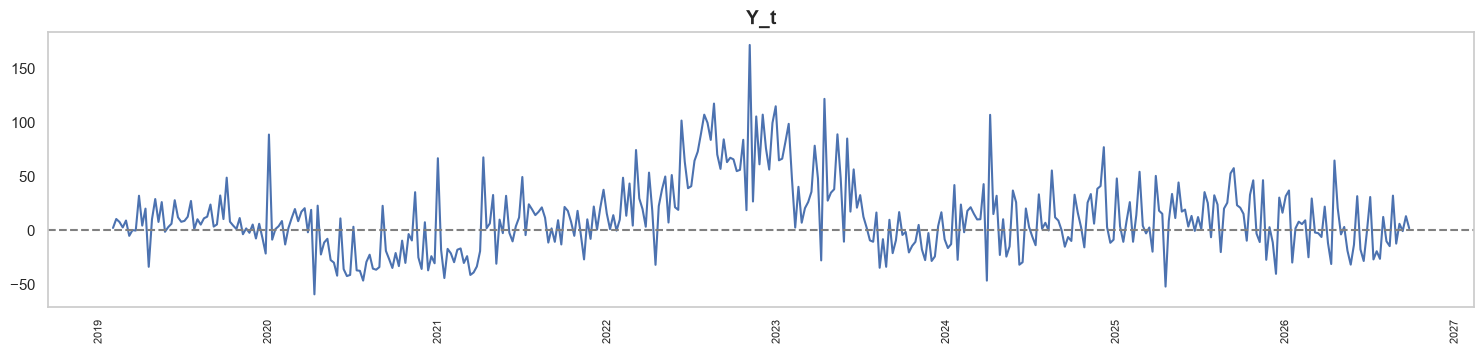

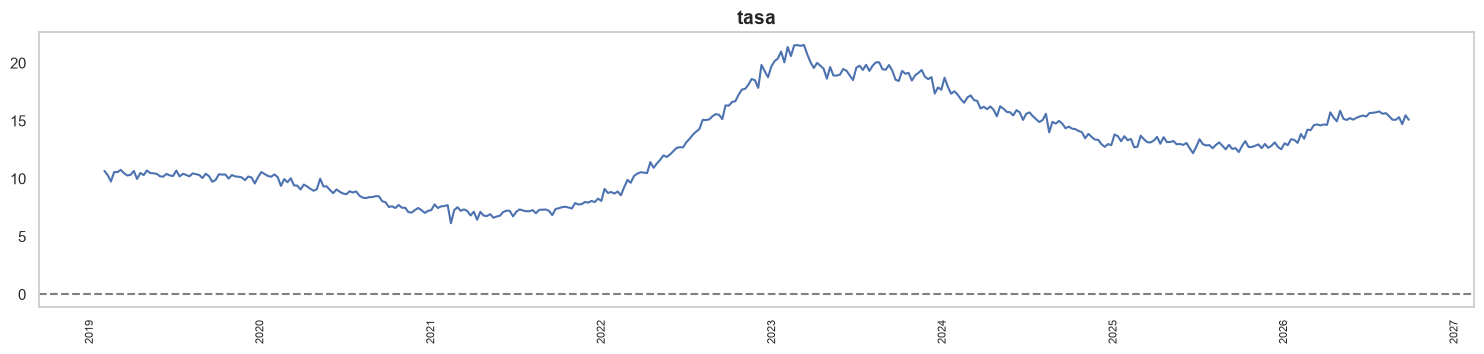

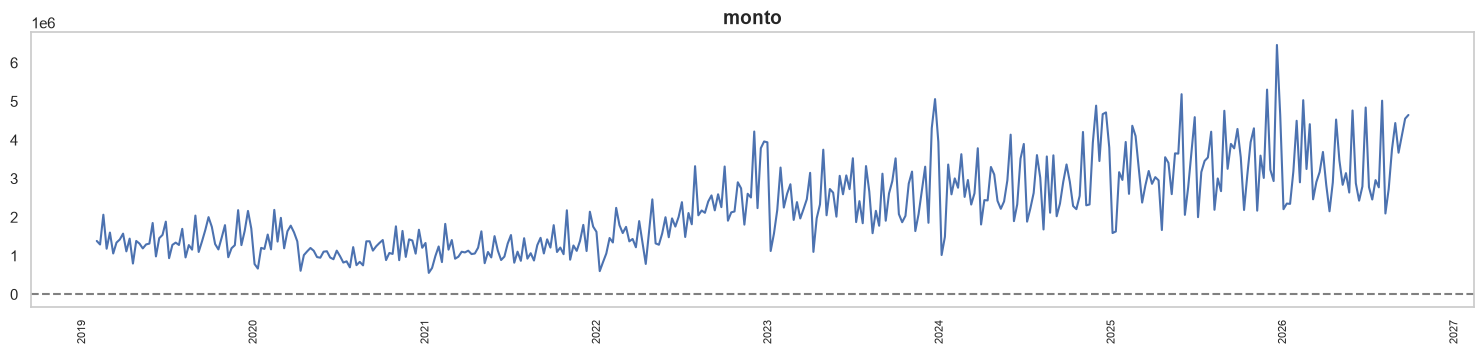

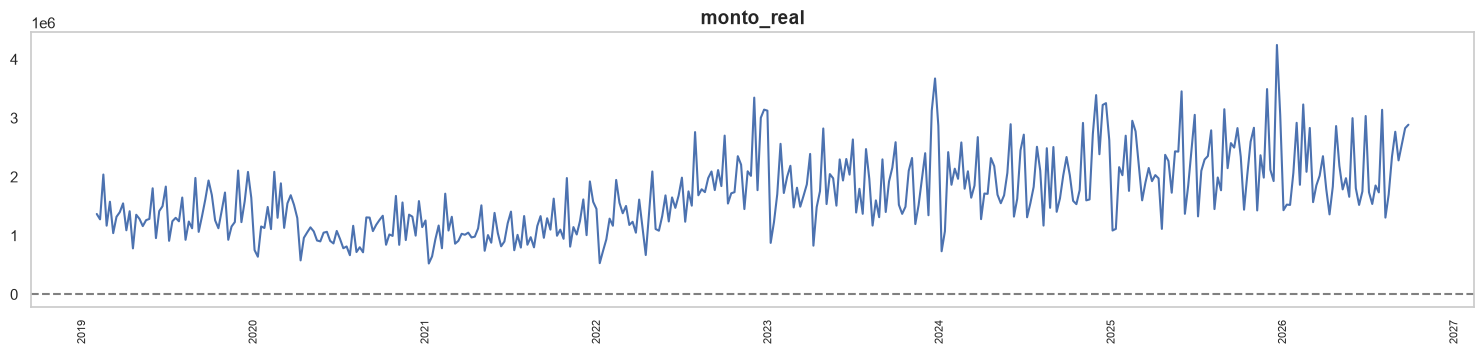

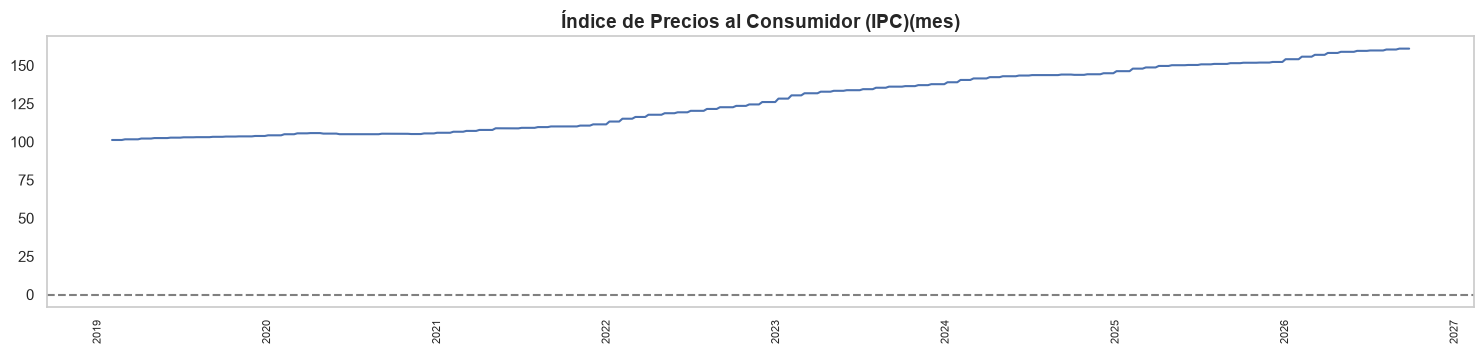

In [ ]:
ax = df[(df["producto"].isin(["Créditos Comerciales (Ordinario)"]))].tail(400)

for i in ["Y_t", "tasa", "monto", "monto_real", "IPC(mes)"]:
    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(15, 3.7))
    sns.lineplot(data=ax, x="fecha", y=i, color="b", markersize = 5)
    plt.title(i, fontsize=14, fontweight="bold")
    plt.xlabel("", fontsize=12)
    plt.ylabel("", fontsize=12)
    plt.xticks(rotation=90, fontsize = 8)
    plt.axhline(0, color = "gray", linestyle = "--")
    plt.tight_layout()
    plt.grid(None)
    plt.show()

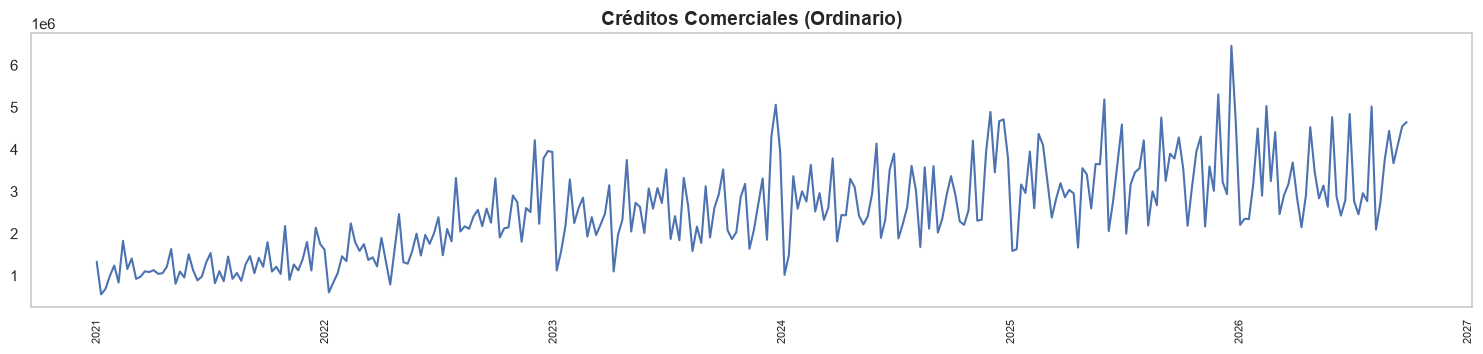

In [223]:
for i in df["producto"].unique():
    ax = df[df["producto"] == i].tail(300)

    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(15, 3.7))
    sns.lineplot(data=ax, x="fecha", y="monto", color="b", markersize = 5)  # y_vari_anual_monto
    plt.title(i, fontsize=14, fontweight="bold")
    plt.xlabel("", fontsize=12)
    plt.ylabel("", fontsize=12)
    plt.xticks(rotation=90, fontsize = 8)
    # plt.axhline(0, color = "gray", linestyle = "--")
    plt.tight_layout()
    plt.grid(None)
    plt.show()